# 36. NewCollege: matched single-sensor calibration rollouts (two IMUs + one LiDAR)

Compare the same two **frozen** networks as notebook 32 using **real** RealSense IMU, Ouster IMU, and Ouster LiDAR measurements.

**Evaluation protocol, identical in spirit to notebook 32:** each window starts with the nominal calibration for **all three sensors**. For a test case, perturb **exactly one selected sensor** by a known SO(3) rotation and/or time offset. Both models receive the same perturbed calibration and physical measurements. During each rollout, apply corrections **only to the selected sensor and selected parameter types**; the other two sensors remain at their nominal values. Repeat for each sensor, including LiDAR. This is an oracle-isolated fault diagnostic, not GT-free automatic calibration.

**Common coordinate frame:** the infrared camera `cam0` (the same `/camera/infra1/image_rect_raw` topic in both Kalibr files) is used to express the three provided extrinsics. Consequently, the LiDAR **is not fixed to identity** and is evaluated as a calibration variable just like both IMUs. The common spatial coordinate frame is an unavoidable choice of gauge, not a fixed-LiDAR assumption.

**Reference quality:** archive/Kalibr rotations and translations are nominal calibration references, not independently certified ground truth. Absolute IMU-vs-LiDAR clock offsets are not completely verified. Differences in predicted tau are therefore measured relative to the selected *nominal* timing values, and must not be described as certified clock errors.

**Observability:** nominal three-sensor Fisher targets are computed/cached separately from the perturbation-specific model inputs. Changing from identity to nominal initialization changes the observability linearization; the old cache must not be reused. No model weights are trained here.

## 1. Paths and experiment controls

Required: both raw IMU CSV directories, `lidar_odometry.csv`, and the three YAML files under `04_calibration/kalibr_output/`. Ground-truth trajectories and raw PCD/infra archives are not required for this matched single-fault test.

All three calibrations are initialized from the supplied **nominal extrinsics** expressed in the common `cam0` camera frame. The controlled experiment changes only one sensor at a time. This intentionally supplies the two healthy sensors' nominal calibrations to the network, as notebook 32 does.

In [20]:
from pathlib import Path

RUN_NAME = 'newcollege_single_sensor_nominal'
NEWCOLLEGE_ROOT = Path('/mnt/d/Downloads/MobRobLab/NewCollegeDataset')
DATASET_ROOT = NEWCOLLEGE_ROOT / '01_short_experiment'
LIDAR_ODOMETRY_CSV = NEWCOLLEGE_ROOT / 'lidar_odometry.csv'
REALSENSE_IMU_DIR = DATASET_ROOT / 'raw_format' / 'realsense_imu'
OUSTER_IMU_DIR = DATASET_ROOT / 'raw_format' / 'ouster_imu'
CALIBRATION_FOLDER = NEWCOLLEGE_ROOT / '04_calibration'
CALIBRATION_ZIP = NEWCOLLEGE_ROOT / '04_calibration.zip'
REALSENSE_IMU_NAME = None
OUSTER_IMU_NAME = None
OLD_PROJECT_SRC = None  # Path('~/Skoltech/phd_proposal/src').expanduser() only if imports fail

# KAIST is used ONLY as a local stream/metadata dataclass *schema* template, never as measurement input.
KAIST_TEMPLATE_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
KAIST_TEMPLATE_LIDAR_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset').expanduser()
KAIST_TEMPLATE_SEQUENCE = 'Urban38'

BASELINE_CHECKPOINT = Path('runs/kaist_pooled_calibration_paired_002.16_correction_only/best.pt')
OBSERVABILITY_CHECKPOINT = Path('runs/kaist_pooled_calibration_paired_002.15_observability_output/joint_best.pt')
MODEL_LABELS = ('Calibration-only', 'Joint + observability')
CALIBRATION_KEYS = ('imu_realsense', 'imu_ouster', 'lidar')
NETWORK_SLOT_TO_PHYSICAL_SOURCE = {'imu_realsense':'RealSense IMU (gyro + accel)', 'imu_ouster':'Ouster IMU (gyro + accel)', 'lidar':'Ouster LiDAR odometry (SE3)'}
STREAM_CALIBRATION_KEYS = {'gyro':'imu_realsense','accel':'imu_realsense','gyro_ouster':'imu_ouster','accel_ouster':'imu_ouster','lidar':'lidar'}

TARGET_IMU_FREQUENCY_HZ = 100.0
MAX_IMU_FILES = None
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
MIN_IMU_SAMPLES_PER_WINDOW = 8
MIN_LIDAR_EDGES_PER_WINDOW = 2
MAX_WINDOWS = None
MAX_IMU_SAMPLE_GAP_S = 0.5

# Nominal reference tau from notebook 17 (approximate, not independently verified).
TAU_REALSENSE_REFERENCE_S = 0.11101
# The archive only gives relative camera/IMU timing; Ouster absolute tau remains unknown.
# Set to a *verified* value if available, otherwise Ouster tau scoring is explicitly provisional.
TAU_OUSTER_REFERENCE_S = None
OUSTER_TAU_REFERENCE_VERIFIED = False

DEVICE_NAME = 'cuda'
MODEL_DTYPE_NAME = 'float32'
RANDOM_SEED = 12345
MODEL_DROPOUT = 0.0

ONE_STEP_WINDOW_COUNT = 8
ONE_STEP_ANGLES_DEG = (0.0, 5.0, 20.0, 45.0, 90.0, 130.0, 160.0, 175.0)
ONE_STEP_SIGNS = (-1, 1)
ONE_STEP_AXES = (0, 1, 2)
RUN_COMBINED_ONE_STEP = True
COMBINED_ANGLES_DEG = (45.0, 130.0)
COMBINED_TAU_MS = (-150.0, 150.0)
RUN_TAU_ONLY_ONE_STEP = True
TAU_ONLY_MS = (-250.0, -150.0, 0.0, 150.0, 250.0)

ROLLOUT_START = 0
ROLLOUT_NUM_WINDOWS = 40  # None for all consecutive windows in the current physical segment
ROLLOUT_ANGLES_DEG = (45.0, 90.0, 130.0, 160.0, 175.0)
ROLLOUT_AXES = (0, 1, 2)
ROLLOUT_SIGNS = (1,)
RUN_MIXED_ROLLOUTS = True
MIXED_ROTVEC_DEG = ((30.0, -40.0, 20.0), (80.0, 15.0, -25.0))
MIXED_TAU_MS = (-150.0, 150.0)
RUN_TAU_ONLY_ROLLOUTS = True
ROLLOUT_TAU_ONLY_MS = (-150.0, 150.0)
ROTATION_GAIN = 1.0
TAU_GAIN = 1.0
MAX_ROTATION_STEP_DEG = None
ROTATION_CONVERGENCE_DEG = 5.0
TAU_CONVERGENCE_MS = 15.0
STABLE_LAST_N_WINDOWS = 10

BUILD_OBSERVABILITY = True
REBUILD_OBSERVABILITY = False
USE_NJIT_OBSERVABILITY = True
CACHE_SAVE_INTERVAL = 25
OBSERVABILITY_MAX_WINDOWS = None  # Set to None after the first successful Fisher-cache smoke run
OBS_LAMBDA = 0.25
OBS_REL_TOL = 1e-10
OBS_CALIBRATION_SCALE = (0.0872664626,)*3 + (0.05,)*3 + (0.015,)
GYRO_RESIDUAL_STD_RADPS = 0.002
ACCEL_RESIDUAL_STD_MPS2 = 0.05
LIDAR_ROTATION_RESIDUAL_STD_RAD = 0.02
LIDAR_TRANSLATION_RESIDUAL_STD_M = 0.10

SAVE_RESULTS = True
OUT_SUBDIR = 'newcollege_comparison'

## 2. Imports and preflight

`new_college_dataset` may live in the older `phd_proposal/src`, whereas `obscalib` lives in `nn-obs-calib/src`. Set `OLD_PROJECT_SRC` above if needed. Preflight checks both IMU directories and the **correct root-level** `lidar_odometry.csv`; no nonexistent second LiDAR is requested. An explicit warning describes the out-of-distribution model adapter.


In [21]:
import copy
import dataclasses
import hashlib
import inspect
import json
import sys
import time
import zipfile
from dataclasses import replace
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm
from scipy.spatial.transform import Rotation as SciPyRotation
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run this notebook inside nn-obs-calib (src/obscalib not found).')
sys.path.insert(0, str(ROOT / 'src'))
if OLD_PROJECT_SRC is not None:
    sys.path.insert(0, str(Path(OLD_PROJECT_SRC).expanduser()))

from new_college_dataset import load_imus
from new_college_dataset.lidar import load_lidar_data_csv
from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.data.structures import WindowBatch
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.training.checkpoint import load_training_checkpoint
from obscalib.observability.estimators import ObservabilityMatrixEstimator
from obscalib.observability.layout import CalibrationParameterLayout
from obscalib.observability.mappings import dimensionless_soft_projector_observability
from obscalib.observability.numerics import ObservabilityNumericsConfig
from obscalib.observability.structures import ObservabilityResult

DEVICE = torch.device(DEVICE_NAME)
MODEL_DTYPE = getattr(torch, MODEL_DTYPE_NAME)
OUT = ROOT / 'runs' / OUT_SUBDIR / RUN_NAME
OUT.mkdir(parents=True, exist_ok=True)
BASELINE_CHECKPOINT = BASELINE_CHECKPOINT if BASELINE_CHECKPOINT.is_absolute() else ROOT / BASELINE_CHECKPOINT
OBSERVABILITY_CHECKPOINT = OBSERVABILITY_CHECKPOINT if OBSERVABILITY_CHECKPOINT.is_absolute() else ROOT / OBSERVABILITY_CHECKPOINT
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

required_paths = [REALSENSE_IMU_DIR, OUSTER_IMU_DIR, LIDAR_ODOMETRY_CSV, BASELINE_CHECKPOINT, OBSERVABILITY_CHECKPOINT, KAIST_TEMPLATE_DATASET_ROOT, KAIST_TEMPLATE_LIDAR_ROOT]
missing = [str(p) for p in required_paths if not Path(p).exists()]
if missing:
    raise FileNotFoundError('Missing required files or folders:\n' + '\n'.join(missing))
if not CALIBRATION_FOLDER.is_dir() and not CALIBRATION_ZIP.is_file():
    raise FileNotFoundError(f'Need calibration YAML under {CALIBRATION_FOLDER} or in {CALIBRATION_ZIP}.')
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(), '| project root', ROOT)
print('NewCollege root:', NEWCOLLEGE_ROOT)
for label, directory in (('RealSense', REALSENSE_IMU_DIR), ('Ouster IMU', OUSTER_IMU_DIR)):
    print(label, 'CSV count:', len(list(directory.glob('*.csv'))), '| first:', [p.name for p in sorted(directory.glob('*.csv'))[:3]])
print('Physical streams:', STREAM_CALIBRATION_KEYS)


torch 2.7.1+cu126 | CUDA True | project root /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
NewCollege root: /mnt/d/Downloads/MobRobLab/NewCollegeDataset
RealSense CSV count: 1 | first: ['data.csv']
Ouster IMU CSV count: 1 | first: ['data.csv']
Physical streams: {'gyro': 'imu_realsense', 'accel': 'imu_realsense', 'gyro_ouster': 'imu_ouster', 'accel_ouster': 'imu_ouster', 'lidar': 'lidar'}


## 3. Import both IMUs and Ouster LiDAR odometry

First attempt the notebook-17 `load_imus()` loader for **both** IMU directories. A limited CSV fallback supports `sec,nsec,wx,wy,wz,ax,ay,az` files when the old loader is format-specific. No fixed time-shift is applied to raw sensor timestamps. Both are restricted to a common physical observation span with LiDAR. Explicit LiDAR scan-boundary times take precedence over inferred boundaries.

**Pseudo-LiDAR construction:** integrate Ouster gyroscope angular velocity over each real Ouster LiDAR scan interval. The output is `T_{I_k I_{k+1}}` with a genuine gyro-integrated rotation and **zero translation because the IMU does not provide independent translation odometry**. This does not make it an independent LiDAR stream.

In [22]:
def scan_boundaries(data):
    relative = np.asarray(data.relative_poses_se3, dtype=np.float64)
    if relative.ndim != 3 or relative.shape[1:] != (4, 4):
        raise ValueError(f'Expected relative poses [N,4,4], got {relative.shape}')
    N = len(relative)
    explicit = None if data.scan_timestamps_s is None else np.asarray(data.scan_timestamps_s, dtype=np.float64)
    midpoints = np.asarray(data.timestamps_s, dtype=np.float64)
    if explicit is not None and len(explicit) == N + 1:
        times = explicit
    elif len(midpoints) == N + 1:
        times = midpoints
    elif len(midpoints) == N and N > 1:
        times = np.empty(N + 1, dtype=np.float64)
        times[1:-1] = 0.5 * (midpoints[:-1] + midpoints[1:])
        times[0] = 2 * midpoints[0] - times[1]
        times[-1] = 2 * midpoints[-1] - times[-2]
        print('Warning: scan boundaries inferred from midpoint timestamps; verify LiDAR CSV semantics.')
    else:
        raise ValueError(f'Cannot associate {N} relative poses with scan times: boundaries={None if explicit is None else len(explicit)}, midpoint={len(midpoints)}')
    if not np.isfinite(times).all() or not np.all(np.diff(times) > 0):
        raise ValueError('LiDAR scan times are not finite/strictly increasing; check timestamp sorting and chronology.')
    if not np.allclose(relative[:, 3, :], [0, 0, 0, 1], atol=1e-4):
        raise ValueError('LiDAR relative poses are not homogeneous transforms.')
    if np.max(np.abs(np.linalg.det(relative[:, :3, :3]) - 1)) > 0.02:
        raise ValueError('LiDAR relative rotations have invalid determinants.')
    return times, relative


def load_imu_recording(directory, selected_name, label):
    """Use the original NewCollege parser; fallback only for the known sec/nsec + wx...az CSV layout."""
    try:
        recordings = load_imus(directory, target_frequency_hz=TARGET_IMU_FREQUENCY_HZ, max_files=MAX_IMU_FILES)
    except Exception as exception:
        recordings = None
        print(f'{label}: load_imus() failed ({type(exception).__name__}: {exception}); trying generic column-based CSV fallback.')
    if recordings is not None:
        if selected_name is None and len(recordings) != 1:
            raise ValueError(f'{label} has multiple independently returned recordings {list(recordings)}; set the exact *_IMU_NAME in configuration. Do not silently combine separate IMU time bases.')
        name = selected_name if selected_name is not None else next(iter(recordings))
        if name not in recordings:
            raise KeyError(f'{label} recording {name!r} not found; available: {list(recordings)}')
        recording = recordings[name]
        times = np.asarray(recording.timestamps_s, dtype=np.float64)
        gyro_values = np.asarray(recording.gyro_radps, dtype=np.float32)
        accel_values = np.asarray(recording.accel_mps2, dtype=np.float32)
        print(f'{label}: loaded via new_college_dataset.load_imus, name={name!r}')
    else:
        files = sorted(directory.glob('*.csv'))
        if MAX_IMU_FILES is not None:
            files = files[:MAX_IMU_FILES]
        if not files:
            raise FileNotFoundError(f'No IMU CSV files in {directory}')
        segments = []
        required = ('sec', 'nsec', 'wx', 'wy', 'wz', 'ax', 'ay', 'az')
        for path in files:
            frame = pd.read_csv(path, skipinitialspace=True)
            frame.columns = [str(column).strip().lower().replace('[rad s^-1]', '').replace('[m s^-2]', '').strip() for column in frame.columns]
            aliases = {column.split()[0]: column for column in frame.columns}
            if any(name not in aliases for name in required):
                raise ValueError(f'Cannot interpret {path}: columns={list(frame.columns)}; expected sec,nsec,wx,wy,wz,ax,ay,az')
            pieces = [pd.to_numeric(frame[aliases[name]], errors='coerce').to_numpy(dtype=np.float64) for name in required]
            segments.append(np.column_stack(pieces))
        values = np.concatenate(segments, axis=0)
        values = values[np.isfinite(values).all(axis=1)]
        values = values[np.argsort(values[:, 0] + 1e-9 * values[:, 1], kind='stable')]
        times = values[:, 0] + 1e-9 * values[:, 1]
        keep = np.r_[True, np.diff(times) > 0]
        values, times = values[keep], times[keep]
        gyro_values = values[:, 2:5].astype(np.float32)
        accel_values = values[:, 5:8].astype(np.float32)
        # Limit fallback rate without interpolation or fabricating new measurements.
        if TARGET_IMU_FREQUENCY_HZ is not None:
            bins = np.floor((times - times[0]) * TARGET_IMU_FREQUENCY_HZ + 1e-8).astype(np.int64)
            indices = np.r_[True, np.diff(bins) > 0]
            times, gyro_values, accel_values = times[indices], gyro_values[indices], accel_values[indices]
        print(f'{label}: fallback CSV loader, files={len(files)}')
    if len(times) < 3 or len(times) != len(gyro_values) or len(times) != len(accel_values) or not np.all(np.diff(times) > 0):
        raise ValueError(f'{label} IMU times/measurements inconsistent after import.')
    return times, gyro_values, accel_values


rs_ts, rs_gyro, rs_accel = load_imu_recording(REALSENSE_IMU_DIR, REALSENSE_IMU_NAME, 'RealSense')
ou_ts, ou_gyro, ou_accel = load_imu_recording(OUSTER_IMU_DIR, OUSTER_IMU_NAME, 'Ouster IMU')
lidar_data = load_lidar_data_csv(LIDAR_ODOMETRY_CSV)
lidar_scan_abs, lidar_edges = scan_boundaries(lidar_data)

# Never extrapolate IMU trajectories outside the intersection of all sensor clocks.
start_abs = max(rs_ts[0], ou_ts[0], lidar_scan_abs[0])
end_abs = min(rs_ts[-1], ou_ts[-1], lidar_scan_abs[-1])
if end_abs - start_abs < 2 * WINDOW_DURATION_S:
    raise ValueError(f'Only {end_abs-start_abs:.3f}s overlap all three sensors. Check unix/relative timestamps and time bases.')
origin = start_abs
rs_ts = rs_ts - origin
ou_ts = ou_ts - origin
lidar_scan_times = lidar_scan_abs - origin


print(f'RealSense: {len(rs_ts)} samples; Ouster IMU: {len(ou_ts)} samples; LiDAR: {len(lidar_edges)} actual SE3 edges')
print(f'Common time span: {end_abs-start_abs:.1f}s; shared origin: {origin:.9f}')


RealSense: loaded via new_college_dataset.load_imus, name='realsense_imu_data'
Ouster IMU: loaded via new_college_dataset.load_imus, name='ouster_imu_data'
RealSense: 153017 samples; Ouster IMU: 153014 samples; LiDAR: 15300 actual SE3 edges
Common time span: 1530.0s; shared origin: 1583836591.185165882


## 4. Load all three nominal calibrations in a common camera frame

Both Kalibr camchains identify `cam0` as `/camera/infra1/image_rect_raw`. We use that **common camera coordinate system** to express the three sensor-to-body transforms:

- `T_C0_REALSENSE_IMU = T_cam_imu` from the RealSense Kalibr result.
- `T_C0_OUSTER_IMU = T_cam_imu` from the Ouster Kalibr result.
- `T_C0_LIDAR = T_C0_OUSTER_IMU @ T_OUSTER_IMU_L` from the Ouster mounting calibration.

This is not a LiDAR-reference frame: **every sensor has a nominal, generally non-identity SE(3) transform**. None is fixed by the one-sensor update policy; which sensor is perturbed varies across experiments. As in notebook 32, healthy sensors are held at the nominal calibration only within each controlled diagnostic.

**Timing caveat:** the Kalibr file pair provides a relative camera/IMU timing relation. `TAU_REALSENSE_REFERENCE_S=0.11101` is a previously estimated LiDAR-relative value, while the absolute Ouster IMU offset is not known. Its `0` fallback is a provisional nominal choice, *not* true timing ground truth. LiDAR nominal tau is `0` by the timestamp datum, but LiDAR tau is still perturbed and corrected in isolated tests.

In [23]:
def read_calibration_yaml(relative):
    relative = relative.lstrip('/')
    relative = '04_calibration/' + relative
    unpacked_path = NEWCOLLEGE_ROOT / relative
    if unpacked_path.is_file():
        return yaml.safe_load(unpacked_path.read_text(encoding='utf-8'))
    if CALIBRATION_ZIP.is_file():
        with zipfile.ZipFile(CALIBRATION_ZIP) as archive:
            if relative in archive.namelist():
                return yaml.safe_load(archive.read(relative).decode('utf-8'))
    raise FileNotFoundError(f'Calibration YAML missing: {relative}')

ou_mount = read_calibration_yaml('04_calibration/kalibr_output/ouster_imu_lidar_transforms.yaml')
kalibr_ou = read_calibration_yaml('04_calibration/kalibr_output/cam-ouster-imu/camchain-ouster_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
kalibr_rs = read_calibration_yaml('04_calibration/kalibr_output/cam-realsense-imu/camchain-realsense_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
assert kalibr_ou['cam0']['rostopic'] == kalibr_rs['cam0']['rostopic'] == '/camera/infra1/image_rect_raw', 'Kalibr cam0 frames differ; cannot compose nominal transforms.'

def matrix_from_mount(entry):
    T = np.eye(4, dtype=np.float64)
    T[:3, :3] = SciPyRotation.from_quat(entry['rotation']).as_matrix()
    T[:3, 3] = np.asarray(entry['translation'], dtype=np.float64)
    return T

T_L_OUSTER_IMU = matrix_from_mount(ou_mount['os1_imu_to_os1_lidar'])
T_OUSTER_IMU_L = matrix_from_mount(ou_mount['os1_lidar_to_os1_imu'])
np.testing.assert_allclose(T_L_OUSTER_IMU @ T_OUSTER_IMU_L, np.eye(4), atol=1e-5)
T_C0_OUSTER_IMU = np.asarray(kalibr_ou['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_REALSENSE_IMU = np.asarray(kalibr_rs['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_LIDAR = T_C0_OUSTER_IMU @ T_OUSTER_IMU_L

# Check that changing the common frame does not change the known relative IMU calibration.
T_L_REALSENSE_IMU = T_L_OUSTER_IMU @ np.linalg.inv(T_C0_OUSTER_IMU) @ T_C0_REALSENSE_IMU
np.testing.assert_allclose(np.linalg.inv(T_C0_LIDAR) @ T_C0_REALSENSE_IMU, T_L_REALSENSE_IMU, atol=1e-5)

kalibr_delta_rs = float(kalibr_rs['cam0']['timeshift_cam_imu'])
kalibr_delta_ou = float(kalibr_ou['cam0']['timeshift_cam_imu'])
relative_imu_clock_shift_s = kalibr_delta_rs - kalibr_delta_ou
print(f'Kalibr camera-relative IMU shift difference: {relative_imu_clock_shift_s:+.6f} s')
print('This difference does NOT establish absolute IMU offsets relative to LiDAR.')

BODY_FRAME = 'camera0_infra1'
reference_transform = {'imu_realsense': T_C0_REALSENSE_IMU, 'imu_ouster': T_C0_OUSTER_IMU, 'lidar': T_C0_LIDAR}
reference_tau = {'imu_realsense': float(TAU_REALSENSE_REFERENCE_S), 'imu_ouster': float(TAU_OUSTER_REFERENCE_S) if TAU_OUSTER_REFERENCE_S is not None else 0.0, 'lidar': 0.0}
reference_tau_verified = {'imu_realsense': False, 'imu_ouster': bool(OUSTER_TAU_REFERENCE_VERIFIED and TAU_OUSTER_REFERENCE_S is not None), 'lidar': False}
if TAU_OUSTER_REFERENCE_S is None:
    print('WARNING: Using provisional nominal Ouster tau = 0.0 s. This is NOT verified clock ground truth.')
for key, T in reference_transform.items():
    np.testing.assert_allclose(T[3], [0, 0, 0, 1], atol=1e-10)
    np.testing.assert_allclose(T[:3, :3].T @ T[:3, :3], np.eye(3), atol=1e-5)
    assert np.linalg.det(T[:3, :3]) > 0.999
    print(f'Nominal T_{BODY_FRAME}<-{key}:\n{T}')
assert not np.allclose(reference_transform['lidar'], np.eye(4), atol=1e-3), 'LiDAR calibration must not be hardwired to identity.'

# EXACTLY AS IN NOTEBOOK 32: nominal/healthy calibrations are the input dataset states.
# The selected fault will be injected later by perturb_one().
INITIAL_TRANSFORM = {key: reference_transform[key].copy() for key in CALIBRATION_KEYS}
INITIAL_TAU = {key: float(reference_tau[key]) for key in CALIBRATION_KEYS}
print(f'All sensor initial states = nominal calibration in the common {BODY_FRAME} frame; perturb only the selected sensor later.')

# A KAIST example supplies only the installed WindowBatch/stream/metadata dataclass layout.
# No KAIST measurements enter NewCollege inference.
template_rig = KAISTRigCalibration(T_B_I=np.eye(4), T_B_L=np.eye(4), tau_imu_s=0.0, tau_lidar_s=0.0)
template_specs = build_kaist_sequence_specs(sequence_names=[KAIST_TEMPLATE_SEQUENCE], kaist_dataset_root=KAIST_TEMPLATE_DATASET_ROOT, lidar_pose_root=KAIST_TEMPLATE_LIDAR_ROOT)
template_ds = KAISTCalibrationDataset(template_specs, template_rig, WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR), measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
template = collate_windows([template_ds[0]])
assert {'gyro', 'accel', 'lidar'}.issubset(template.streams), f'Unexpected KAIST stream templates: {tuple(template.streams)}'
assert all(dataclasses.is_dataclass(template.streams[key]) and dataclasses.is_dataclass(template.metadata[key]) for key in ('gyro', 'accel', 'lidar'))
for key in ('gyro', 'accel', 'lidar'):
    print('Schema template:', key, 'stream fields:', [f.name for f in dataclasses.fields(template.streams[key])])

Kalibr camera-relative IMU shift difference: +0.075664 s
This difference does NOT establish absolute IMU offsets relative to LiDAR.
Nominal T_camera0_infra1<-imu_realsense:
[[ 0.99999395  0.00301154  0.00174074  0.0058566 ]
 [-0.00301404  0.99999443  0.00143592  0.01737982]
 [-0.00173641 -0.00144116  0.99999745 -0.01595566]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-imu_ouster:
[[ 0.70992163 -0.70414167  0.01399269  0.01562753]
 [ 0.02460003  0.00493623 -0.99968519 -0.01981648]
 [ 0.70385092  0.71004236  0.02082624 -0.07544143]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-lidar:
[[-0.70992163  0.70414167  0.01399269  0.00249784]
 [-0.02460003 -0.00493623 -0.99968519  0.00861384]
 [-0.70385092 -0.71004236  0.02082624 -0.07207614]
 [ 0.          0.          0.          1.        ]]
All sensor initial states = nominal calibration in the common camera0_infra1 frame; perturb only the selected sensor later.
Schema template: 

## 5. Construct genuine two-IMU/one-LiDAR windows

Five physical streams: RealSense gyro/accel, Ouster gyro/accel, and LiDAR relative SE(3) poses. Both IMUs have independent `calibration_key` metadata. Every window starts from **all three nominal camera0-frame calibrations**, including the non-identity LiDAR extrinsic, exactly as notebook 32 starts from its nominal rig. Only the later diagnostic function perturbs one sensor. Windows never bridge unsupported recording gaps.

In [24]:
def make_stream_from_template(base_stream, values_np, end_times_np, start_times_np=None):
    values = torch.as_tensor(np.asarray(values_np), dtype=base_stream.values.dtype).unsqueeze(0)
    times = torch.as_tensor(np.asarray(end_times_np), dtype=base_stream.timestamps.dtype).unsqueeze(0)
    updates = {'values':values, 'timestamps':times}
    names = {f.name for f in dataclasses.fields(base_stream)}
    if 'interval_start_timestamps' in names:
        starts = getattr(base_stream,'interval_start_timestamps')
        if start_times_np is not None:
            updates['interval_start_timestamps'] = torch.as_tensor(np.asarray(start_times_np),dtype=times.dtype).unsqueeze(0)
        elif starts is not None:
            updates['interval_start_timestamps'] = None
    elif start_times_np is not None:
        raise RuntimeError('Installed LiDAR stream has no interval_start_timestamps; inspect repository schema.')
    for field in dataclasses.fields(base_stream):
        name = field.name
        if name in updates:continue
        old = getattr(base_stream,name)
        if isinstance(old,torch.Tensor) and old.ndim>=2 and old.shape[1]==base_stream.values.shape[1]:
            if name in ('mask','valid_mask','sample_mask'):
                updates[name] = torch.ones((1,values.shape[1]),dtype=old.dtype)
            elif name in ('lengths','num_samples'):
                updates[name] = torch.tensor([values.shape[1]],dtype=old.dtype)
            else:
                raise RuntimeError(f'Unrecognized length-dependent stream field: {name}')
    stream=replace(base_stream,**updates)
    assert stream.values.shape[0]==1 and stream.timestamps.shape == (1,stream.values.shape[1])
    return stream

# Keep the original recording-relative timestamps for window selection, then convert each window to its own local time origin.
window_start_candidates = np.arange(0.0,end_abs-origin-WINDOW_DURATION_S+1e-8,WINDOW_STRIDE_S)
if MAX_WINDOWS is not None:window_start_candidates=window_start_candidates[:MAX_WINDOWS]
window_starts, window_slices = [], []
for a in window_start_candidates:
    z=a+WINDOW_DURATION_S
    rs_sel=np.where((rs_ts>=a)&(rs_ts<z))[0]
    ou_sel=np.where((ou_ts>=a)&(ou_ts<z))[0]
    lidar_sel=np.where((lidar_scan_times[:-1]>=a)&(lidar_scan_times[1:]<=z+1e-9))[0]
    if min(len(rs_sel),len(ou_sel))<MIN_IMU_SAMPLES_PER_WINDOW or len(lidar_sel)<MIN_LIDAR_EDGES_PER_WINDOW:continue
    if np.max(np.diff(rs_ts[rs_sel]))>MAX_IMU_SAMPLE_GAP_S or np.max(np.diff(ou_ts[ou_sel]))>MAX_IMU_SAMPLE_GAP_S:continue
    if max(len(rs_sel),len(ou_sel),len(lidar_sel))>MAX_SAMPLES_PER_SENSOR:
        raise ValueError(f'Window {a:.3f}s exceeds max sample count. Lower IMU target frequency or subsample explicitly.')
    window_starts.append(float(a));window_slices.append((rs_sel,ou_sel,lidar_sel))
if not window_slices:raise RuntimeError('No valid three-sensor windows. Check timestamp conventions, recording gaps, and LiDAR scan boundaries.')

# Metadata clones retain sensor MODALITY (IMU gyro/accel or LiDAR) but route to distinct calibration keys.
def clone_metadata(original,calibration_key):
    names={f.name for f in dataclasses.fields(original)}
    if 'calibration_key' not in names:raise RuntimeError('Installed StreamMetadata lacks calibration_key.')
    return replace(original,calibration_key=calibration_key)

class NewCollegeWindowDataset:
    calibration_keys=CALIBRATION_KEYS
    def __len__(self):return len(window_slices)
    def __getitem__(self,index):
        rs_sel,ou_sel,lidar_sel=window_slices[index]
        # A different origin for EACH 5-second window, as in the KAIST dataset.
        # Do this while the NumPy arrays are still float64. Keep the continuous
        # recording timestamps above untouched for the physical-alignment sweeps.
        t0 = window_starts[index]
        rs_t = rs_ts[rs_sel] - t0
        ou_t = ou_ts[ou_sel] - t0
        lidar_t0 = lidar_scan_times[lidar_sel] - t0
        lidar_t1 = lidar_scan_times[lidar_sel + 1] - t0

        streams={
            'gyro':make_stream_from_template(template.streams['gyro'],rs_gyro[rs_sel],rs_t),
            'accel':make_stream_from_template(template.streams['accel'],rs_accel[rs_sel],rs_t),
            'gyro_ouster':make_stream_from_template(template.streams['gyro'],ou_gyro[ou_sel],ou_t),
            'accel_ouster':make_stream_from_template(template.streams['accel'],ou_accel[ou_sel],ou_t),
            'lidar':make_stream_from_template(template.streams['lidar'],lidar_edges[lidar_sel],lidar_t1,lidar_t0),
        }
        metadata={key:clone_metadata(template.metadata['gyro' if key.startswith('gyro') else 'accel' if key.startswith('accel') else 'lidar'],calibration_key) for key,calibration_key in STREAM_CALIBRATION_KEYS.items()}
        # These are the nominal reference states for all three sensors, as in notebook 32.
        initial={key:CalibrationState(transform=torch.tensor(INITIAL_TRANSFORM[key],dtype=MODEL_DTYPE)[None],time_offset=torch.tensor([[INITIAL_TAU[key]]],dtype=MODEL_DTYPE)) for key in CALIBRATION_KEYS}
        return WindowBatch(streams=streams,current_calibration=initial,metadata=metadata,targets=None,dataset_indices=torch.tensor([index],dtype=torch.long))
    def window_indices_for_sequence(self,name):
        if name!='NewCollege':raise KeyError(name)
        return list(range(len(self)))
    def sequence_name_for_window(self,index):return 'NewCollege'

nc_dataset=NewCollegeWindowDataset()
print('Valid consecutive physical windows:',len(nc_dataset),'from',len(window_start_candidates),'candidates')
first=nc_dataset[0]
assert tuple(first.current_calibration)==CALIBRATION_KEYS
assert set(first.streams)==set(STREAM_CALIBRATION_KEYS)
for k,stream in first.streams.items():
    assert first.metadata[k].calibration_key==STREAM_CALIBRATION_KEYS[k]
    print(k,tuple(stream.values.shape),'timestamps',float(stream.timestamps.min()),float(stream.timestamps.max()),'kind',str(first.metadata[k]))
assert first.streams['gyro_ouster'].values.shape[-1]==3 and first.streams['accel_ouster'].values.shape[-1]==3
assert first.streams['lidar'].values.shape[-2:]==(4,4)
for k in CALIBRATION_KEYS:
    np.testing.assert_allclose(first.current_calibration[k].transform.numpy()[0],INITIAL_TRANSFORM[k])
    np.testing.assert_allclose(first.current_calibration[k].time_offset.numpy(),[[INITIAL_TAU[k]]])
# Check late windows as well: merely testing window 0 does not catch the old bug.
for sample_index in sorted({0,len(nc_dataset)//2,len(nc_dataset)-1}):
    sample=nc_dataset[sample_index]
    for sensor_stream in sample.streams.values():
        assert bool(torch.isfinite(sensor_stream.timestamps).all())
        assert float(sensor_stream.timestamps.min()) >= -1e-5
        assert float(sensor_stream.timestamps.max()) <= WINDOW_DURATION_S+1e-4
        starts=getattr(sensor_stream,'interval_start_timestamps',None)
        if starts is not None:
            assert bool(torch.all(sensor_stream.timestamps>starts))
            assert float(starts.min()) >= -1e-5
    assert abs(float(sample.streams['gyro'].timestamps[0,0])-(rs_ts[window_slices[sample_index][0][0]]-window_starts[sample_index])) < 1e-4
print('Nominal calibration and per-window 0-5 s timestamps across recording: PASS')

def to_device(window):return window_batch_to(window,DEVICE,dtype=MODEL_DTYPE)

Valid consecutive physical windows: 305 from 305 candidates
gyro (1, 501, 3) timestamps 0.0 4.999995231628418 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
accel (1, 501, 3) timestamps 0.0 4.999995231628418 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
gyro_ouster (1, 500, 3) timestamps 0.0036530494689941406 4.993648529052734 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
accel_ouster (1, 500, 3) timestamps 0.0036530494689941406 4.993648529052734 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
lidar (1, 49, 4, 4) timestamps 0.19741368293762207 4.997517108917236 kind 

In [25]:
provenance = {
    'dataset_root': str(NEWCOLLEGE_ROOT),
    'physical_sources': NETWORK_SLOT_TO_PHYSICAL_SOURCE,
    'stream_calibration_key': STREAM_CALIBRATION_KEYS,
    'evaluation_policy': 'notebook32_matched_single_sensor_perturbation_and_selected_dof_updates',
    'common_body_coordinate_frame': BODY_FRAME,
    'model_input_initial_transforms': 'all_three_nominal_camera0_extrinsics',
    'model_input_initial_tau': 'nominal_timing_estimates_not_verified_for_all_sensors',
    'reference_source': 'Ouster mount YAML + both Kalibr camera-to-IMU YAMLs',
    'reference_transform': {key: value.tolist() for key, value in reference_transform.items()},
    'reference_tau_s': reference_tau,
    'reference_tau_verified': reference_tau_verified,
    'kalibr_relative_imu_clock_shift_s': relative_imu_clock_shift_s,
    'warning': 'Reference extrinsics are nominal, not independently certified GT. This is oracle single-fault evaluation, not GT-free deployment.',
}
if SAVE_RESULTS:
    (OUT / 'sensor_provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
print('Sensor routing:', NETWORK_SLOT_TO_PHYSICAL_SOURCE)
print('Coordinate frame:', BODY_FRAME)

Sensor routing: {'imu_realsense': 'RealSense IMU (gyro + accel)', 'imu_ouster': 'Ouster IMU (gyro + accel)', 'lidar': 'Ouster LiDAR odometry (SE3)'}
Coordinate frame: camera0_infra1


## 6. Frozen checkpoints with sensor-type-preserving routing

Use the same shared Transformer, pooler, and calibration head. Route physical calibration keys in the order RealSense IMU, Ouster IMU, Ouster LiDAR. The two IMUs remain gyro+accel in `GeometryProcessor`, not LiDAR. Smoke test verifies every output and correct token ordering before expensive evaluation.


In [26]:
from torch import nn
D_MODEL=128
SHARED_FEATURE_DIM=128
model_config=PooledCalibrationModelConfig(transformer=TransformerConfig(input_dim=8,d_model=128,n_heads=8,num_layers=12,dim_feedforward=512,dropout=MODEL_DROPOUT,num_summary_tokens=1,activation='gelu'),mlp=MLPConfig(hidden_dims=(256,128),output_dim=SHARED_FEATURE_DIM,activation='gelu',dropout=0.0),pooler=CalibrationPoolerConfig(n_heads=8,dropout=0.0,calibration_context_dim=0),head=PooledCalibrationHeadConfig(calibration_context_dim=0,hidden_dims=(128,64),activation='gelu',dropout=0.0))

class CalibrationWithObservability(nn.Module):
    def __init__(self,calibration_model,observability_head):
        super().__init__();self.calibration_model=calibration_model;self.observability_head=observability_head
    def forward(self,tokens,calibration_context=None):
        correction=self.calibration_model(tokens,calibration_context)
        return correction,self.observability_head(correction.shared_features)

def build_obs_head():return nn.Sequential(nn.Linear(128,128),nn.GELU(),nn.Linear(128,7),nn.Sigmoid())

baseline=PooledCalibrationModel(model_config).to(DEVICE,dtype=MODEL_DTYPE)
joint=CalibrationWithObservability(PooledCalibrationModel(model_config),build_obs_head()).to(DEVICE,dtype=MODEL_DTYPE)
base_payload=load_training_checkpoint(BASELINE_CHECKPOINT,model=baseline,map_location=DEVICE,restore_rng_state=False)
joint_payload=load_training_checkpoint(OBSERVABILITY_CHECKPOINT,model=joint,map_location=DEVICE,restore_rng_state=False)
baseline.eval().requires_grad_(False);joint.eval().requires_grad_(False)
BACKBONES={MODEL_LABELS[0]:baseline,MODEL_LABELS[1]:joint.calibration_model}
geometry_processor=GeometryProcessor()
tokenizer=Tokenizer(measurement_dim=6,calibration_keys=CALIBRATION_KEYS)

def calibration_forward(window,states,model):
    # Only physical measurements and candidate calibration states enter the encoder.
    canonical=geometry_processor(window.streams,window.metadata,states)
    tokens=tokenizer(canonical,observability=None)
    if tokens.x.shape[-1]!=8 or tuple(tokens.calibration_keys)!=CALIBRATION_KEYS:
        raise RuntimeError(f'Unexpected token layout {tuple(tokens.x.shape)} / {tuple(tokens.calibration_keys)}. Native multi-IMU routing needs a geometry/tokenizer adaptation; never relabel IMU as LiDAR.')
    context={key:calibration_state_to_context(states[key]) for key in CALIBRATION_KEYS}
    result=model(tokens,context)
    if result.shared_features.shape[1]!=len(CALIBRATION_KEYS):raise RuntimeError('Unexpected per-sensor features shape.')
    return result

@torch.inference_mode()
def both_forward(window,states):
    results={label:calibration_forward(window,states,backbone) for label,backbone in BACKBONES.items()}
    head_output=joint.observability_head(results[MODEL_LABELS[1]].shared_features)
    return results,head_output

smoke=to_device(nc_dataset[0]);outputs,obs=both_forward(smoke,smoke.current_calibration)
assert obs.shape==(1,3,7) and torch.isfinite(obs).all()
for name,out in outputs.items():
    for key in CALIBRATION_KEYS:
        assert out.predictions[key].delta_xi.shape==(1,6) and out.predictions[key].delta_tau.shape==(1,1)
        assert torch.isfinite(out.predictions[key].delta_xi).all() and torch.isfinite(out.predictions[key].delta_tau).all()
print('Native RealSense + Ouster IMU + Ouster LiDAR model forward: PASS')
print('Checkpoint epochs:',base_payload.get('epoch'),joint_payload.get('epoch'))


Native RealSense + Ouster IMU + Ouster LiDAR model forward: PASS
Checkpoint epochs: 97 116


## 7. Three-sensor physical observability, computed once and cached

Use **all five physical streams** and a 21-dimensional calibration layout (3 sensor blocks × 7 DoF), with two distinct IMU gyro/accel factor sets. The LiDAR relative-motion chain supplies the *measurement trajectory*; its non-identity camera0 extrinsic transforms that trajectory into the common camera0 coordinates. The Fisher target is computed at the **nominal calibration state**, as in notebook 32, not at a random identity initialization. If `ObservabilityMatrixEstimator` does not yet support generic multi-IMU stream metadata, it will raise an explicit error: do not silently fall back to a two-sensor FIM.

The resulting Fisher scores are conditional on assumed noise covariances and the LiDAR-derived trajectory; those estimates can be poor for a strongly wrong initialization.

In [27]:
def diagonal_lidar_cov(rotation_std,translation_std):
    std=torch.tensor([rotation_std]*3+[translation_std]*3,dtype=torch.float64)
    return torch.diag(std.square())

covariance={
    'gyro':torch.eye(3,dtype=torch.float64)*GYRO_RESIDUAL_STD_RADPS**2,
    'accel':torch.eye(3,dtype=torch.float64)*ACCEL_RESIDUAL_STD_MPS2**2,
    'gyro_ouster':torch.eye(3,dtype=torch.float64)*GYRO_RESIDUAL_STD_RADPS**2,
    'accel_ouster':torch.eye(3,dtype=torch.float64)*ACCEL_RESIDUAL_STD_MPS2**2,
    'lidar':diagonal_lidar_cov(LIDAR_ROTATION_RESIDUAL_STD_RAD,LIDAR_TRANSLATION_RESIDUAL_STD_M),
}
physical_layout=CalibrationParameterLayout.from_calibration_keys(CALIBRATION_KEYS)
obs_numerics=ObservabilityNumericsConfig(relative_tolerance=OBS_REL_TOL,parameter_scales=None)
OBS_PARAMETER_NAMES=('phi_x','phi_y','phi_z','rho_x','rho_y','rho_z','tau')
assert physical_layout.total_dimension==21

def lidar_derived_body_trajectory_provider(measurements, metadata, calibration, reference_timebase):
    # Use measured Ouster LiDAR odometry to reconstruct a trajectory in the camera0 frame.
    # The trajectory must be reconstructed using the selected stream and its extrinsic.
    stream_key = reference_timebase.stream_key

    if stream_key != "lidar":
        raise ValueError(f"Expected a LiDAR reference stream, got {stream_key!r}.")
    if stream_key not in measurements or stream_key not in metadata:
        raise KeyError(f"Missing reference LiDAR stream {stream_key!r}.")

    stream = measurements[stream_key]
    if stream.interval_start_timestamps is None:
        raise ValueError("Reference LiDAR stream must carry interval_start_timestamps.")

    calibration_key = metadata[stream_key].calibration_key
    T_B_L_current = calibration[calibration_key].transform
    if T_B_L_current.ndim == 3:
        if T_B_L_current.shape[0] != 1:
            raise ValueError("Unbatched trajectory provider expects one calibration state.")
        T_B_L_current = T_B_L_current[0]

    T_B_L_current = T_B_L_current.to(device="cpu", dtype=torch.float64)
    T_L_B_current = torch.linalg.inv(T_B_L_current)
    relative_lidar_poses = stream.values
    interval_starts = stream.interval_start_timestamps
    interval_ends = stream.timestamps

    if relative_lidar_poses.ndim == 4:
        if relative_lidar_poses.shape[0] != 1:
            raise ValueError("Trajectory provider expects an unbatched stream or singleton batch.")
        relative_lidar_poses = relative_lidar_poses[0]
        interval_starts = interval_starts[0]
        interval_ends = interval_ends[0]

    relative_lidar_poses = relative_lidar_poses.to(device="cpu", dtype=torch.float64)
    interval_starts = interval_starts.to(device="cpu", dtype=torch.float64)
    interval_ends = interval_ends.to(device="cpu", dtype=torch.float64)
    reference_timestamps = reference_timebase.timestamps.to(device="cpu", dtype=torch.float64)

    poses_by_time = {}
    current_pose = torch.eye(4, dtype=torch.float64)
    for interval_index in range(relative_lidar_poses.shape[0]):
        start_time = float(interval_starts[interval_index].item())
        end_time = float(interval_ends[interval_index].item())
        poses_by_time[start_time] = current_pose
        current_pose = current_pose @ (T_B_L_current @ relative_lidar_poses[interval_index] @ T_L_B_current)
        poses_by_time[end_time] = current_pose

    available_times = np.asarray(sorted(poses_by_time), dtype=float)
    trajectory_poses = []
    for timestamp in reference_timestamps:
        query_time = float(timestamp.item())
        nearest_index = int(np.argmin(np.abs(available_times - query_time)))
        nearest_time = float(available_times[nearest_index])
        if abs(nearest_time - query_time) > 1e-6:
            raise ValueError(f"Could not construct nominal pose at reference timestamp {query_time:.9f}; nearest available time is {nearest_time:.9f}.")
        trajectory_poses.append(poses_by_time[nearest_time])

    return torch.stack(trajectory_poses, dim=0)


kwargs={'calibration_layout':physical_layout,'trajectory_provider':lidar_derived_body_trajectory_provider,'residual_covariance_by_stream':covariance}
optional={
    'gravity_world':torch.tensor([0,0,9.81],dtype=torch.float64),
    'gyro_bias_by_calibration_key':{'imu_realsense':torch.zeros(3,dtype=torch.float64),'imu_ouster':torch.zeros(3,dtype=torch.float64)},
    'numerics':obs_numerics,'njit':USE_NJIT_OBSERVABILITY,'reference_stream_key':'lidar',
}
sig=inspect.signature(ObservabilityMatrixEstimator.__init__)
for name,value in optional.items():
    if name in sig.parameters:kwargs[name]=value
missing=[name for name,p in sig.parameters.items() if name!='self' and p.default==inspect.Parameter.empty and p.kind in (inspect.Parameter.POSITIONAL_ONLY,inspect.Parameter.POSITIONAL_OR_KEYWORD,inspect.Parameter.KEYWORD_ONLY) and name not in kwargs]
if missing:raise RuntimeError(f'Missing required estimator arguments: {missing}; signature {sig}')
obs_estimator=ObservabilityMatrixEstimator(**kwargs)

def compute_initial_guess_scores(index):
    w=nc_dataset[index]
    # Compute Fisher information at the nominal calibration (the no-fault initial state).
    forward_sig=inspect.signature(obs_estimator.forward)
    try:
        if 'metadata' in forward_sig.parameters:
            result=obs_estimator(w.streams,w.current_calibration,w.metadata)
        else:
            result=obs_estimator(w.streams,w.current_calibration)
    except Exception as exc:
        raise RuntimeError('Three-sensor physical observability failed. The local estimator may not support multiple IMU streams or the native metadata routing. Update the estimator explicitly; do not replace an IMU with pseudo-LiDAR.') from exc
    if not isinstance(result,ObservabilityResult) or result.raw is None or not hasattr(result.raw,'fisher_information_matrix'):
        raise TypeError('ObservabilityResult.raw.fisher_information_matrix missing.')
    fisher=result.raw.fisher_information_matrix
    if fisher.ndim==3:
        if fisher.shape[0]!=1:raise ValueError(tuple(fisher.shape))
        fisher=fisher[0]
    if fisher.shape!=(physical_layout.total_dimension,physical_layout.total_dimension):
        raise RuntimeError(f'Expected 21x21 physical Fisher from both IMUs + LiDAR, got {tuple(fisher.shape)}.')
    mapped=dimensionless_soft_projector_observability(fisher,physical_layout,calibration_scale=OBS_CALIBRATION_SCALE,lambda_value_setting=OBS_LAMBDA)
    flat=mapped[0].detach().cpu().float()
    per_sensor=torch.stack([flat[physical_layout.block_for(key).parameter_slice] for key in CALIBRATION_KEYS])
    if per_sensor.shape!=(3,7) or not torch.isfinite(per_sensor).all() or not bool(((per_sensor>=0)&(per_sensor<=1)).all()):
        raise RuntimeError(f'Invalid physical Fisher score at index {index}: {per_sensor}')
    return per_sensor

if BUILD_OBSERVABILITY:
    obs_estimator.eval()
    with torch.no_grad():
        first_scores=compute_initial_guess_scores(0)
    print('Physical three-sensor FIM scores, first window:',first_scores)

Physical three-sensor FIM scores, first window: tensor([[5.0025e-01, 5.0032e-01, 1.8651e-01, 2.9794e-15, 7.6703e-20, 4.3230e-17,
         8.4265e-02],
        [5.0025e-01, 5.0032e-01, 1.8650e-01, 1.0406e-25, 1.2466e-28, 4.7855e-39,
         1.6103e-01],
        [1.0481e-03, 1.3534e-03, 5.9843e-04, 7.4124e-31, 1.3068e-30, 1.1755e-30,
         7.1707e-03]])


In [28]:
def signature_of(path):
    path=Path(path)
    return {'path':str(path.resolve()),'size':path.stat().st_size,'mtime_ns':path.stat().st_mtime_ns}

def folder_signature(folder):return [signature_of(p) for p in sorted(Path(folder).glob('*.csv'))]

metadata={
    'version':5,'timestamp_frame':'window_relative_float64_before_tensor','dataset':'NewCollege','target_kind':'real_two_imu_one_lidar_fim_at_nominal_camera0_calibration',
    'common_body_coordinate_frame':BODY_FRAME,'window_count':len(nc_dataset),'window_starts':[round(x,9) for x in window_starts],
    'window_duration':WINDOW_DURATION_S,'window_stride':WINDOW_STRIDE_S,'max_samples':MAX_SAMPLES_PER_SENSOR,
    'initial_transform':{k:INITIAL_TRANSFORM[k].tolist() for k in CALIBRATION_KEYS},
    'initial_tau':INITIAL_TAU,'calibration_keys':CALIBRATION_KEYS,'stream_calibration':STREAM_CALIBRATION_KEYS,
    'obs_scale':OBS_CALIBRATION_SCALE,'lambda':OBS_LAMBDA,'relative_tolerance':OBS_REL_TOL,'njit':USE_NJIT_OBSERVABILITY,
    'covariance':{k:v.tolist() for k,v in covariance.items()},
    'realsense_files':folder_signature(REALSENSE_IMU_DIR),'ouster_imu_files':folder_signature(OUSTER_IMU_DIR),
    'lidar_file':signature_of(LIDAR_ODOMETRY_CSV),
}
cache_hash=hashlib.sha256(json.dumps(metadata,sort_keys=True).encode()).hexdigest()[:16]
CACHE_DIR=ROOT/'outputs'/'observability_targets'/'newcollege'
CACHE_DIR.mkdir(parents=True,exist_ok=True)
CACHE_FILE=CACHE_DIR/f'physical_two_imus_one_lidar_{cache_hash}.pt'

def load_or_compute_observability():
    N=len(nc_dataset) if OBSERVABILITY_MAX_WINDOWS is None else min(len(nc_dataset),OBSERVABILITY_MAX_WINDOWS)
    values=torch.full((len(nc_dataset),len(CALIBRATION_KEYS),7),torch.nan,dtype=torch.float32)
    complete=torch.zeros(len(nc_dataset),dtype=torch.bool)
    if CACHE_FILE.exists() and not REBUILD_OBSERVABILITY:
        old=torch.load(CACHE_FILE,map_location='cpu',weights_only=True)
        if old.get('metadata')==metadata and tuple(old['values'].shape)==tuple(values.shape):
            values=old['values'];complete=old['complete'];print('Reusing completed physical FIM windows:',int(complete.sum()))
    def save():
        tmp=CACHE_FILE.with_suffix('.tmp')
        torch.save({'metadata':metadata,'values':values,'complete':complete,'calibration_keys':CALIBRATION_KEYS},tmp)
        tmp.replace(CACHE_FILE)
    if not BUILD_OBSERVABILITY:
        if not bool(complete[:N].all()):print('Scientific Fisher cache incomplete; enable BUILD_OBSERVABILITY for missing targets.')
        return values,complete
    obs_estimator.eval()
    with torch.no_grad():
        for i in tqdm(range(N),desc='NewCollege physical three-sensor FIM'):
            if complete[i]:continue
            try:
                values[i]=compute_initial_guess_scores(i);complete[i]=True
            except Exception as exc:
                save();raise RuntimeError(f'Failed physical Fisher at window {i}, t={window_starts[i]:.3f}s. Cache saved: {CACHE_FILE}') from exc
            if (i+1)%CACHE_SAVE_INTERVAL==0:save()
    save();return values,complete

scientific_obs_values,scientific_obs_complete=load_or_compute_observability()
print('Physical target progress:',int(scientific_obs_complete.sum()),'/',len(nc_dataset),'|',CACHE_FILE)

NewCollege physical three-sensor FIM:   0%|          | 0/305 [00:00<?, ?it/s]

Physical target progress: 305 / 305 | /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/newcollege/physical_two_imus_one_lidar_5b0c3294518de2d2.pt


## 8. Auxiliary observability prediction vs physical Fisher at nominal calibration

Evaluate the auxiliary observability head and the computed 21×21 Fisher score at the **same nominal three-sensor state**. As in notebook 32, this is a diagnostic reference-state calculation; each controlled-perturbation forward in the next sections separately supplies the perturbed candidate state.

Auxiliary obs predictions:   0%|          | 0/305 [00:00<?, ?it/s]

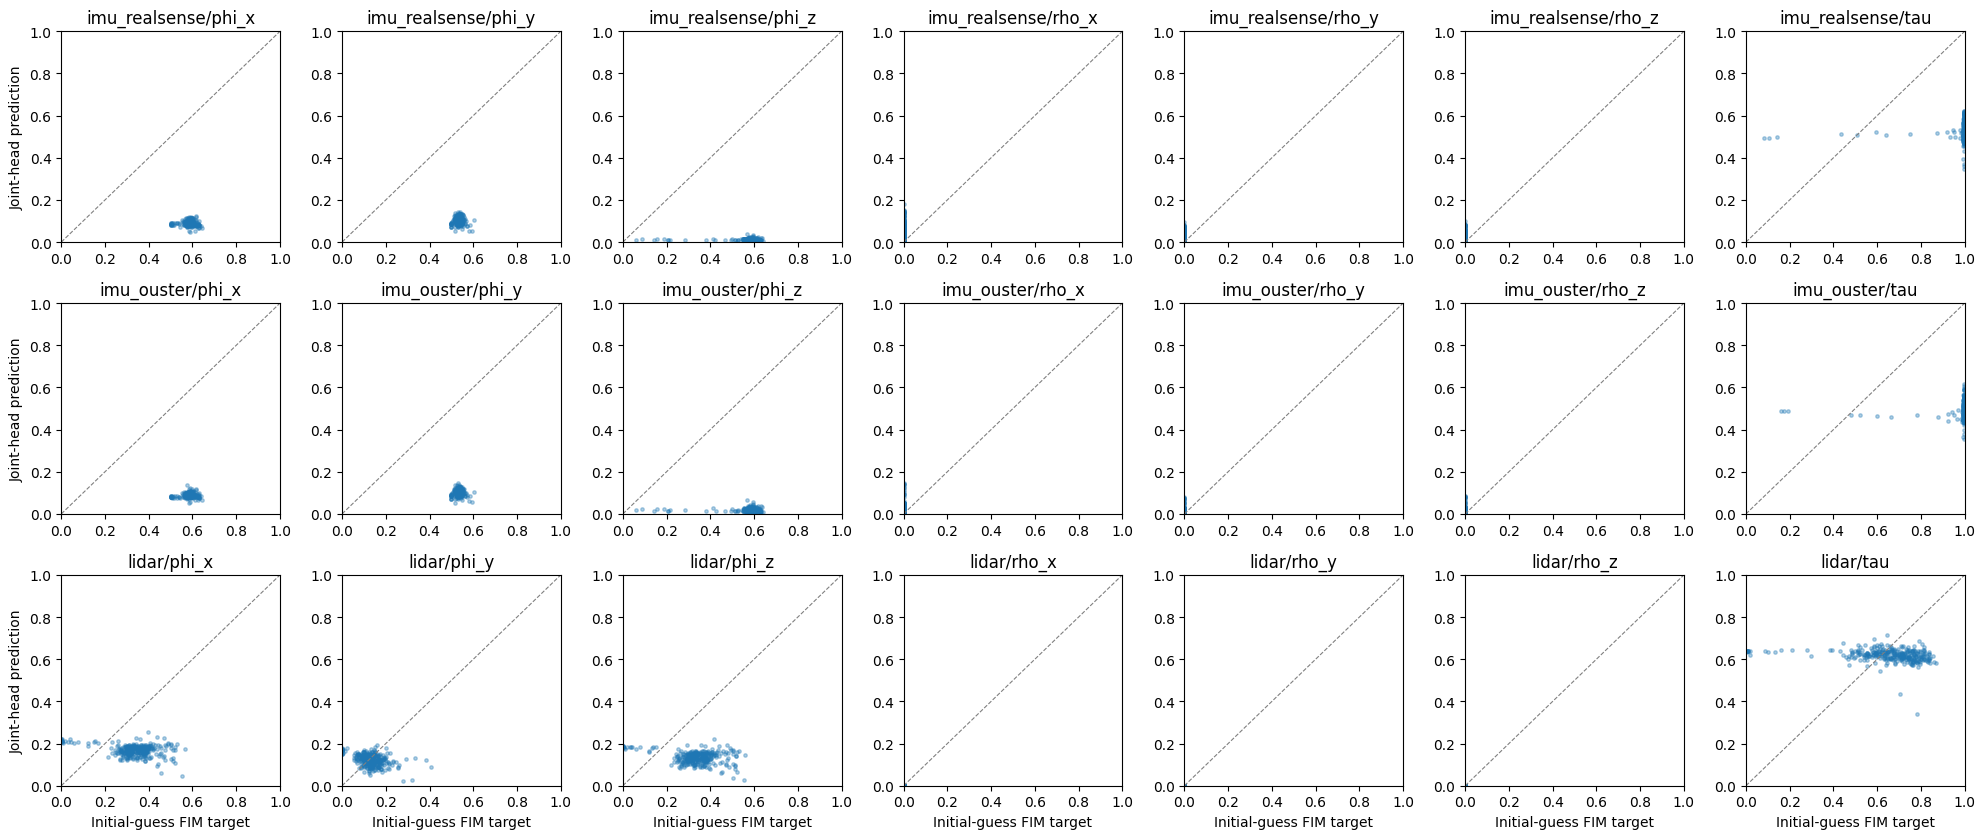

,sensor,dof,n,mae,pearson
0,imu_realsense,phi_x,305,0.493,-0.002
1,imu_realsense,phi_y,305,0.429,-0.035
2,imu_realsense,phi_z,305,0.556,-0.003
3,imu_realsense,rho_x,305,0.045,NaN
4,imu_realsense,rho_y,305,0.025,NaN
5,imu_realsense,rho_z,305,0.025,NaN
6,imu_realsense,tau,305,0.457,0.114
7,imu_ouster,phi_x,305,0.494,0.123
8,imu_ouster,phi_y,305,0.430,-0.017
9,imu_ouster,phi_z,305,0.550,0.001


In [29]:
@torch.inference_mode()
def predicted_initial_guess_obs(indices):
    preds=[]; gt=[]; retained=[]
    for i in tqdm(indices,desc='Auxiliary obs predictions'):
        if not scientific_obs_complete[i]:continue
        w=to_device(nc_dataset[int(i)])
        out=calibration_forward(w,w.current_calibration,joint.calibration_model)
        pred=joint.observability_head(out.shared_features)[0].detach().cpu()
        preds.append(pred[[CALIBRATION_KEYS.index(k) for k in CALIBRATION_KEYS]]);gt.append(scientific_obs_values[i]);retained.append(i)
    if not preds: return None
    return torch.stack(preds).numpy(),torch.stack(gt).numpy(),np.array(retained)

obs_comparison=predicted_initial_guess_obs(np.where(scientific_obs_complete.numpy())[0])
if obs_comparison is not None:
    pred,truth,ids=obs_comparison
    rows=[]
    fig,axes=plt.subplots(len(CALIBRATION_KEYS),7,figsize=(20,8.5),squeeze=False)
    for k,key in enumerate(CALIBRATION_KEYS):
        for j,dof in enumerate(OBS_PARAMETER_NAMES):
            ax=axes[k,j];p=pred[:,k,j];q=truth[:,k,j]
            ax.scatter(q,p,s=6,alpha=.35);ax.plot([0,1],[0,1],'--',lw=.8,color='gray')
            ax.set(xlim=(0,1),ylim=(0,1),title=f'{key}/{dof}')
            if k==len(CALIBRATION_KEYS)-1:ax.set_xlabel('Initial-guess FIM target')
            if j==0:ax.set_ylabel('Joint-head prediction')
            rows.append({'sensor':key,'dof':dof,'n':len(p),'mae':float(np.mean(np.abs(p-q))),'pearson':float(np.corrcoef(p,q)[0,1]) if np.std(p)>1e-10 and np.std(q)>1e-10 else np.nan})
    fig.tight_layout()
    if SAVE_RESULTS:fig.savefig(OUT/'observability_scatter.png',dpi=150)
    plt.show();plt.close(fig)
    obs_metrics=pd.DataFrame(rows)
    display(obs_metrics.round(3))
    if SAVE_RESULTS:obs_metrics.to_csv(OUT/'observability_scores.csv',index=False)
else:print('No completed physical Fisher targets to compare.')


## 9. Notebook-32-style isolated perturbations and scoring

`NewCollegeWindowDataset.current_calibration` is the nominal calibration for **all three sensors**. In a controlled test, construct a copy and perturb **exactly one sensor**. The two healthy sensors remain nominal throughout all forward passes and updates. Applying a correction to the selected sensor does not change its translation and does not touch any other sensor.

The nominal transforms are available to the model only as current *healthy-sensor* calibration values; the selected sensor receives the deliberately **wrong** value. This is the same oracle-fault-isolation protocol as notebook 32, not an automatic fault-detection experiment.

In [30]:
def reference_states(window):
    """Nominal/reference calibration for scoring and single-fault initialization."""
    return {key: CalibrationState(transform=torch.as_tensor(reference_transform[key], device=window.current_calibration[key].transform.device, dtype=window.current_calibration[key].transform.dtype).unsqueeze(0), time_offset=torch.tensor([[reference_tau[key]]], device=window.current_calibration[key].time_offset.device, dtype=window.current_calibration[key].time_offset.dtype)) for key in CALIBRATION_KEYS}

def clone_states(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}

def assert_healthy_sensors_unchanged(reference, states, selected_key):
    for other in CALIBRATION_KEYS:
        if other == selected_key:
            continue
        torch.testing.assert_close(states[other].transform, reference[other].transform, atol=0, rtol=0)
        torch.testing.assert_close(states[other].time_offset, reference[other].time_offset, atol=0, rtol=0)

def so3_error_deg(R_est, R_ref):
    delta = R_ref @ R_est.transpose(-1, -2)
    sin = 0.5 * torch.linalg.vector_norm(torch.stack((delta[..., 2, 1] - delta[..., 1, 2], delta[..., 0, 2] - delta[..., 2, 0], delta[..., 1, 0] - delta[..., 0, 1]), dim=-1), dim=-1)
    cos = 0.5 * (delta.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    return torch.rad2deg(torch.atan2(sin, cos))

def perturb_one(reference, key, rotvec_deg=None, tau_ms=0):
    """Return a nominal calibration copy with only the requested sensor perturbed."""
    if key not in CALIBRATION_KEYS:
        raise KeyError(key)
    states = clone_states(reference)
    rotvec = np.zeros(3) if rotvec_deg is None else np.asarray(rotvec_deg, dtype=float)
    r = torch.as_tensor(rotvec, device=states[key].transform.device, dtype=states[key].transform.dtype).reshape(1, 3)
    T = states[key].transform.clone()
    T[:, :3, :3] = so3_exp(torch.deg2rad(r)) @ T[:, :3, :3]
    states[key] = CalibrationState(transform=T, time_offset=states[key].time_offset + float(tau_ms) / 1000)
    assert_healthy_sensors_unchanged(reference, states, key)
    torch.testing.assert_close(states[key].transform[:, :3, 3], reference[key].transform[:, :3, 3], atol=0, rtol=0)
    return states

def apply_single_update(states, pred, key, update_rotation=True, update_tau=False):
    """Update selected DOFs of selected sensor only; preserve the healthy sensors."""
    if key not in CALIBRATION_KEYS:
        raise KeyError(key)
    updated = clone_states(states)
    old = states[key]
    T = old.transform.clone()
    if update_rotation:
        dr = ROTATION_GAIN * pred.predictions[key].delta_xi[:, :3]
        if MAX_ROTATION_STEP_DEG is not None:
            dr = dr * (np.deg2rad(MAX_ROTATION_STEP_DEG) / dr.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        T[:, :3, :3] = so3_exp(dr) @ T[:, :3, :3]
    new_tau = old.time_offset + (TAU_GAIN * pred.predictions[key].delta_tau if update_tau else 0.0)
    updated[key] = CalibrationState(transform=T, time_offset=new_tau)
    assert_healthy_sensors_unchanged(states, updated, key)
    torch.testing.assert_close(updated[key].transform[:, :3, 3], old.transform[:, :3, 3], atol=0, rtol=0)
    if not update_rotation:
        torch.testing.assert_close(updated[key].transform[:, :3, :3], old.transform[:, :3, :3], atol=0, rtol=0)
    if not update_tau:
        torch.testing.assert_close(updated[key].time_offset, old.time_offset, atol=0, rtol=0)
    return updated

def errors(states, ref, key):
    deg = float(so3_error_deg(states[key].transform[:, :3, :3], ref[key].transform[:, :3, :3]).item())
    ms = float(((states[key].time_offset - ref[key].time_offset).abs() * 1000).item())
    return deg, ms

# Unit tests at the exact semantics used for both model evaluations, including LiDAR.
w = to_device(nc_dataset[0]); ref = reference_states(w)
for key in CALIBRATION_KEYS:
    torch.testing.assert_close(w.current_calibration[key].transform, ref[key].transform, atol=0, rtol=0)
    torch.testing.assert_close(w.current_calibration[key].time_offset, ref[key].time_offset, atol=0, rtol=0)
    for axis in range(3):
        for angle in (0, 30, 90, 175):
            vec = np.zeros(3); vec[axis] = angle
            wrong = perturb_one(w.current_calibration, key, vec)
            assert abs(errors(wrong, ref, key)[0] - angle) < 0.02
            assert_healthy_sensors_unchanged(ref, wrong, key)
print('Notebook 32 matched nominal initialization, one-fault perturbation and healthy-sensor invariants: PASS')

Notebook 32 matched nominal initialization, one-fault perturbation and healthy-sensor invariants: PASS


## 10. Matched one-step tests: perturb one sensor, leave the others nominal

For **each** selected sensor (including LiDAR), run signed X/Y/Z rotation-only, combined rotation+tau, and tau-only cases. The network sees the same physically measured NewCollege windows and the selected sensor's wrong candidate calibration. Its two healthy sensors remain at their nominal archive calibration, exactly as in notebook 32. The zero-angle case measures unnecessary correction from a nominal state.

In [31]:
one_step_indices=np.unique(np.linspace(0,len(nc_dataset)-1,min(len(nc_dataset),ONE_STEP_WINDOW_COUNT),dtype=int))

@torch.inference_mode()
def evaluate_one_step_case(index,key,scenario,axis=None,angle_deg=0.0,tau_ms=0.0):
    w=to_device(nc_dataset[int(index)]);ref=reference_states(w)
    vec=np.zeros(3)
    if axis is not None:vec[axis]=angle_deg
    wrong=perturb_one(w.current_calibration,key,vec,tau_ms)  # Exactly one wrong sensor; the two healthy sensors retain nominal calibration.
    assert_healthy_sensors_unchanged(ref,wrong,key)
    raw,obs=both_forward(w,wrong)
    before_deg,before_ms=errors(wrong,ref,key)
    rows=[]
    for name,out in raw.items():
        after=apply_single_update(wrong,out,key,update_rotation=scenario!='tau_only',update_tau=scenario!='rotation_only')
        assert_healthy_sensors_unchanged(ref,after,key)
        after_deg,after_ms=errors(after,ref,key)
        rows.append({'window_index':int(index),'window_start_s':window_starts[int(index)],'model':name,'scenario':scenario,'sensor':key,'physical_source':NETWORK_SLOT_TO_PHYSICAL_SOURCE[key],'axis':'tau' if axis is None else 'xyz'[axis], 'signed_initial_deg':angle_deg,'initial_tau_ms':tau_ms,'before_deg':before_deg,'after_deg':after_deg,'before_tau_ms':before_ms,'after_tau_ms':after_ms,'improved_rotation':after_deg<before_deg-1e-6,'predicted_step_deg':float(torch.rad2deg(out.predictions[key].delta_xi[:,:3].norm(dim=-1)).item()),'predicted_obs':float(obs[0,CALIBRATION_KEYS.index(key),axis if axis is not None else 6]) if name==MODEL_LABELS[1] else np.nan})
    return rows

one_step_rows=[]
for sensor in tqdm(CALIBRATION_KEYS,desc='One-step sensor'):
    for axis in ONE_STEP_AXES:
        for angle in ONE_STEP_ANGLES_DEG:
            for sign in ((1,) if angle==0 else ONE_STEP_SIGNS):
                for i in one_step_indices:one_step_rows.extend(evaluate_one_step_case(i,sensor,'rotation_only',axis,sign*angle,0))
        if RUN_COMBINED_ONE_STEP:
            for angle in COMBINED_ANGLES_DEG:
                for sign in ONE_STEP_SIGNS:
                    for tau in COMBINED_TAU_MS:
                        for i in one_step_indices:one_step_rows.extend(evaluate_one_step_case(i,sensor,'rotation_tau',axis,sign*angle,tau))
    if RUN_TAU_ONLY_ONE_STEP:
        for tau in TAU_ONLY_MS:
            for i in one_step_indices:one_step_rows.extend(evaluate_one_step_case(i,sensor,'tau_only',None,0,tau))
one_step=pd.DataFrame(one_step_rows)
one_step_summary=one_step.groupby(['model','scenario','sensor','axis','signed_initial_deg','initial_tau_ms'],as_index=False).agg(after_deg=('after_deg','mean'),after_tau_ms=('after_tau_ms','mean'),rotation_improvement_rate=('improved_rotation','mean'),n=('window_index','count'))
display(one_step_summary.round(3))
if SAVE_RESULTS:
    one_step.to_csv(OUT/'one_step_cases.csv',index=False)
    one_step_summary.to_csv(OUT/'one_step_summary.csv',index=False)

One-step sensor:   0%|          | 0/3 [00:00<?, ?it/s]

,model,scenario,sensor,axis,signed_initial_deg,initial_tau_ms,after_deg,after_tau_ms,rotation_improvement_rate,n
0,Calibration-only,rotation_only,imu_ouster,x,-175.0,0.0,166.952,0.000,0.875,8
1,Calibration-only,rotation_only,imu_ouster,x,-160.0,0.0,160.751,0.000,0.500,8
2,Calibration-only,rotation_only,imu_ouster,x,-130.0,0.0,135.189,0.000,0.000,8
3,Calibration-only,rotation_only,imu_ouster,x,-90.0,0.0,115.524,0.000,0.000,8
4,Calibration-only,rotation_only,imu_ouster,x,-45.0,0.0,83.412,0.000,0.000,8
...,...,...,...,...,...,...,...,...,...,...
439,Joint + observability,tau_only,lidar,tau,0.0,-250.0,0.000,249.243,0.000,8
440,Joint + observability,tau_only,lidar,tau,0.0,-150.0,0.000,149.257,0.000,8
441,Joint + observability,tau_only,lidar,tau,0.0,0.0,0.000,1.525,0.000,8
442,Joint + observability,tau_only,lidar,tau,0.0,150.0,0.000,153.512,0.000,8


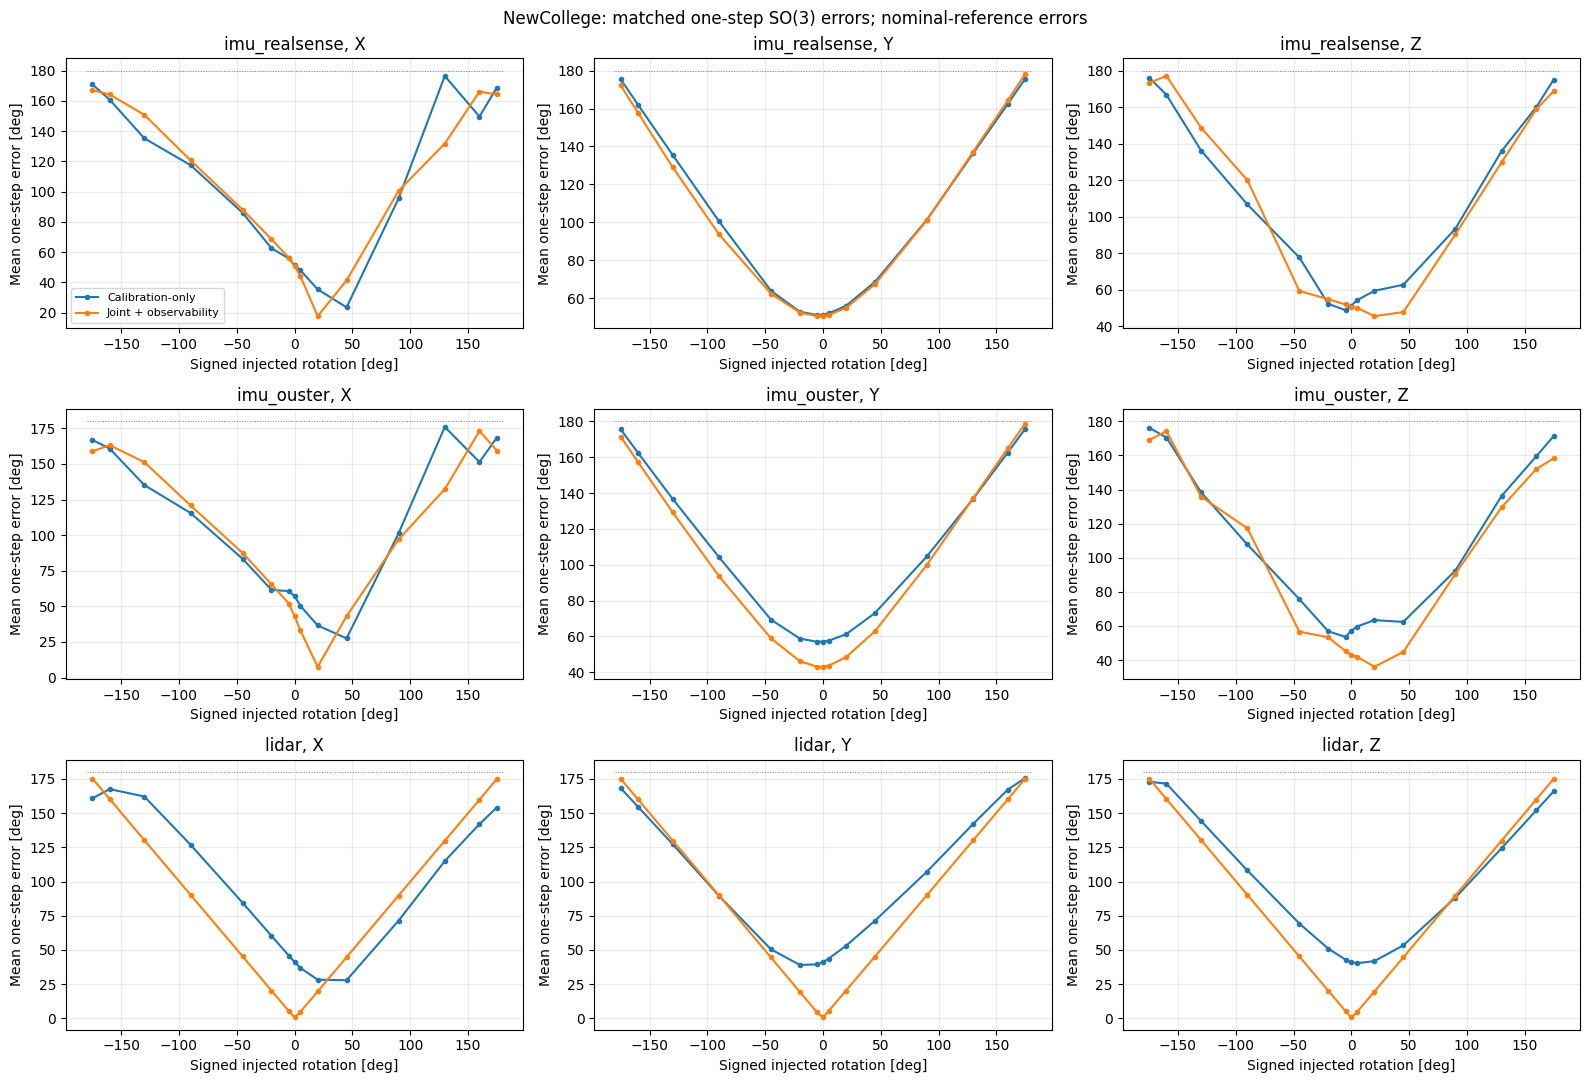

In [32]:
rotation_only=one_step[one_step.scenario=='rotation_only']
fig,axes=plt.subplots(len(CALIBRATION_KEYS),3,figsize=(16,11),squeeze=False)
for i,sensor in enumerate(CALIBRATION_KEYS):
    for j,axis in enumerate('xyz'):
        ax=axes[i,j]
        group=rotation_only[(rotation_only.sensor==sensor)&(rotation_only.axis==axis)]
        for model_name in MODEL_LABELS:
            sub=group[group.model==model_name]
            mean=sub.groupby('signed_initial_deg').after_deg.mean().sort_index()
            ax.plot(mean.index,mean.values,marker='.',label=model_name)
        ax.plot([-180,180],[180,180],':',color='gray',lw=.7)
        ax.set(title=f'{sensor}, {axis.upper()}',xlabel='Signed injected rotation [deg]',ylabel='Mean one-step error [deg]')
        ax.grid(alpha=.25)
        if i==0 and j==0:ax.legend(fontsize=8)
fig.suptitle('NewCollege: matched one-step SO(3) errors; nominal-reference errors')
fig.tight_layout()
if SAVE_RESULTS:fig.savefig(OUT/'one_step_rotation_curves.png',dpi=150)
plt.show();plt.close(fig)

### Nominal initialization verification across the recording

Unlike the earlier identity/zero cold-start experiment, the matched experiment requires **all three sensors** to start at their nominal calibrations in every window. This check verifies that even LiDAR is not silently fixed or reinitialized while constructing NewCollege windows.

In [33]:
nominal_check_indices = np.unique([0, len(nc_dataset) // 2, len(nc_dataset) - 1])
for index in nominal_check_indices:
    w = to_device(nc_dataset[int(index)])
    truth = reference_states(w)
    for sensor in CALIBRATION_KEYS:
        torch.testing.assert_close(w.current_calibration[sensor].transform, truth[sensor].transform, atol=0, rtol=0)
        torch.testing.assert_close(w.current_calibration[sensor].time_offset, truth[sensor].time_offset, atol=0, rtol=0)
        for other in CALIBRATION_KEYS:
            if other != sensor:
                assert errors(w.current_calibration, truth, other)[0] < 0.02
    for sensor in CALIBRATION_KEYS:
        wrong = perturb_one(w.current_calibration, sensor, (20., -10., 30.), tau_ms=150.)
        assert_healthy_sensors_unchanged(truth, wrong, sensor)
        assert errors(wrong, truth, sensor)[0] > 30.0
print(f'Matched nominal calibration for all sensors across {len(nominal_check_indices)} NewCollege windows: PASS')
print('LiDAR is a perturbable calibration key with nominal transform in', BODY_FRAME, 'coordinates.')

Matched nominal calibration for all sensors across 3 NewCollege windows: PASS
LiDAR is a perturbable calibration key with nominal transform in camera0_infra1 coordinates.


## 11. Single-sensor chronological rollouts, as in notebook 32

For every scenario, **all three sensors start at nominal calibration**, then exactly one sensor receives the specified rotation and/or clock fault. Carry the candidate through consecutive five-second windows, applying corrections **only to that sensor**. Rotation-only rollouts hold all clock offsets at their nominal values; tau-only rollouts do not change rotations; mixed rollouts update both rotation and tau for the selected sensor. The two healthy sensors remain fixed at nominal calibration, regardless of whether the selected sensor is RealSense IMU, Ouster IMU, or LiDAR.

`ROLLOUT_NUM_WINDOWS=40` evaluates 200 seconds; use `None` for all consecutive valid windows. This is a controlled oracle-fault-isolation diagnostic, not a simultaneous all-sensor self-calibration test. Ground-truth quality caveats remain for the nominal extrinsics and clock offsets.

In [34]:
rollout_limit = len(nc_dataset) if ROLLOUT_NUM_WINDOWS is None else min(len(nc_dataset), ROLLOUT_START + ROLLOUT_NUM_WINDOWS)
selected_rollout_indices = [ROLLOUT_START]
for next_index in range(ROLLOUT_START + 1, rollout_limit):
    if abs(window_starts[next_index] - window_starts[selected_rollout_indices[-1]] - WINDOW_STRIDE_S) > 1e-5:
        print(f'Chronological segment ends after {len(selected_rollout_indices)} windows: next candidate has a time gap; never stitch discontinuous physical windows.')
        break
    selected_rollout_indices.append(next_index)
if len(selected_rollout_indices) < 2:
    raise ValueError('Fewer than two consecutive valid windows from ROLLOUT_START. Choose a valid continuous segment.')
print(f'Rollout: {len(selected_rollout_indices)} consecutive physical windows, start={window_starts[selected_rollout_indices[0]]:.2f}s, end={window_starts[selected_rollout_indices[-1]]+WINDOW_DURATION_S:.2f}s')

@torch.inference_mode()
def run_rollout(sensor,scenario,rotvec_deg=(0,0,0),tau_ms=0,axis_label='mixed'):
    first=to_device(nc_dataset[selected_rollout_indices[0]])
    nominal=reference_states(first)
    if scenario not in ('rotation_only', 'mixed', 'tau_only'):
        raise ValueError(scenario)
    starting=perturb_one(first.current_calibration,sensor,rotvec_deg,tau_ms)
    assert_healthy_sensors_unchanged(nominal,starting,sensor)
    carry={label:clone_states(starting) for label in MODEL_LABELS}
    start_deg,start_tau=errors(starting,nominal,sensor)
    rows=[]
    def row(label,tstep,window_idx,rotation,tau,obs=np.nan):
        return {'model':label,'scenario':scenario,'sensor':sensor,'physical_source':NETWORK_SLOT_TO_PHYSICAL_SOURCE[sensor],'axis':axis_label,'initial_rotvec_deg':str(tuple(map(float,rotvec_deg))),'initial_tau_ms':float(tau_ms),'step':tstep,'window_index':window_idx,'window_start_s':window_starts[window_idx],'rotation_error_deg':rotation,'tau_error_ms':tau,'predicted_obs':obs}
    for name in MODEL_LABELS:rows.append(row(name,0,selected_rollout_indices[0],start_deg,start_tau))
    for step,index in enumerate(selected_rollout_indices,start=1):
        w=to_device(nc_dataset[index]);ref=reference_states(w)
        # Calibration truth/reference must remain constant throughout the chronological dataset.
        for k in CALIBRATION_KEYS:
            torch.testing.assert_close(ref[k].transform,nominal[k].transform,atol=1e-6,rtol=0)
            torch.testing.assert_close(ref[k].time_offset,nominal[k].time_offset,atol=1e-6,rtol=0)
        for name,backbone in BACKBONES.items():
            result=calibration_forward(w,carry[name],backbone)
            new=apply_single_update(carry[name],result,sensor,update_rotation=scenario!='tau_only',update_tau=scenario!='rotation_only')
            assert_healthy_sensors_unchanged(nominal,new,sensor)
            carry[name]=new
            d,m=errors(new,ref,sensor)
            ob=float(joint.observability_head(result.shared_features)[0,CALIBRATION_KEYS.index(sensor),0:3].mean()) if name==MODEL_LABELS[1] else np.nan
            rows.append(row(name,step,index,d,m,ob))
    return rows

scenarios=[]
for sensor in CALIBRATION_KEYS:
    for ax in ROLLOUT_AXES:
        for magnitude in ROLLOUT_ANGLES_DEG:
            for sign in ROLLOUT_SIGNS:
                v=np.zeros(3);v[ax]=sign*magnitude
                scenarios.append((sensor,'rotation_only',v,0.0,'xyz'[ax]))
    if RUN_MIXED_ROLLOUTS:
        for vec in MIXED_ROTVEC_DEG:
            for tau in MIXED_TAU_MS:scenarios.append((sensor,'mixed',np.array(vec),tau,'mixed'))
    if RUN_TAU_ONLY_ROLLOUTS:
        for tau in ROLLOUT_TAU_ONLY_MS:scenarios.append((sensor,'tau_only',np.zeros(3),tau,'tau'))

all_rollout_rows=[]
for sensor,scenario,vec,tau,axis in tqdm(scenarios,desc='Sequential calibration rollouts'):
    all_rollout_rows.extend(run_rollout(sensor,scenario,rotvec_deg=vec,tau_ms=tau,axis_label=axis))
rollouts=pd.DataFrame(all_rollout_rows)
if SAVE_RESULTS:rollouts.to_csv(OUT/'rollouts_timeseries.csv',index=False)

summary=[]
identifiers=['model','scenario','sensor','axis','initial_rotvec_deg','initial_tau_ms']
for grouping,frame in rollouts.groupby(identifiers,sort=False):
    frame=frame.sort_values('step');rot=frame.rotation_error_deg.to_numpy();tau=frame.tau_error_ms.to_numpy();n=min(STABLE_LAST_N_WINDOWS,len(rot)-1)
    rot_tail,tau_tail=rot[-n:],tau[-n:]
    mode=frame.scenario.iloc[0]
    converged=(mode=='tau_only' or np.all(rot_tail<ROTATION_CONVERGENCE_DEG)) and (mode=='rotation_only' or np.all(tau_tail<TAU_CONVERGENCE_MS))
    summary.append(dict(zip(identifiers,grouping),initial_rot_deg=rot[0],final_rot_deg=rot[-1],best_rot_deg=np.min(rot[1:]),final_tau_ms=tau[-1],best_tau_ms=np.min(tau[1:]),stable_convergence=bool(converged)))
rollout_summary=pd.DataFrame(summary)
display(rollout_summary.round(2))
display(rollout_summary.groupby(['scenario','model']).stable_convergence.agg(['count','mean']))
if SAVE_RESULTS:rollout_summary.to_csv(OUT/'rollouts_summary.csv',index=False)

Rollout: 40 consecutive physical windows, start=0.00s, end=200.00s


Sequential calibration rollouts:   0%|          | 0/63 [00:00<?, ?it/s]

,model,scenario,sensor,axis,initial_rotvec_deg,initial_tau_ms,initial_rot_deg,final_rot_deg,best_rot_deg,final_tau_ms,best_tau_ms,stable_convergence
0,Calibration-only,rotation_only,imu_realsense,x,"(45.0, 0.0, 0.0)",0.0,45.00,167.99,18.09,0.00,0.00,False
1,Joint + observability,rotation_only,imu_realsense,x,"(45.0, 0.0, 0.0)",0.0,45.00,163.41,6.45,0.00,0.00,False
2,Calibration-only,rotation_only,imu_realsense,x,"(90.0, 0.0, 0.0)",0.0,90.00,154.87,103.43,0.00,0.00,False
3,Joint + observability,rotation_only,imu_realsense,x,"(90.0, 0.0, 0.0)",0.0,90.00,166.05,124.38,0.00,0.00,False
4,Calibration-only,rotation_only,imu_realsense,x,"(130.0, 0.0, 0.0)",0.0,130.00,166.55,165.95,0.00,0.00,False
...,...,...,...,...,...,...,...,...,...,...,...,...
121,Joint + observability,mixed,lidar,mixed,"(80.0, 15.0, -25.0)",150.0,85.15,122.77,74.01,313.22,151.41,False
122,Calibration-only,tau_only,lidar,tau,"(0.0, 0.0, 0.0)",-150.0,0.00,0.00,0.00,632.11,8.43,False
123,Joint + observability,tau_only,lidar,tau,"(0.0, 0.0, 0.0)",-150.0,0.00,0.00,0.00,102.75,102.75,False
124,Calibration-only,tau_only,lidar,tau,"(0.0, 0.0, 0.0)",150.0,0.00,0.00,0.00,750.72,206.26,False


count  mean
scenario      model                             
mixed         Calibration-only          12   0.0
              Joint + observability     12   0.0
rotation_only Calibration-only          45   0.0
              Joint + observability     45   0.0
tau_only      Calibration-only           6   0.0
              Joint + observability      6   0.0

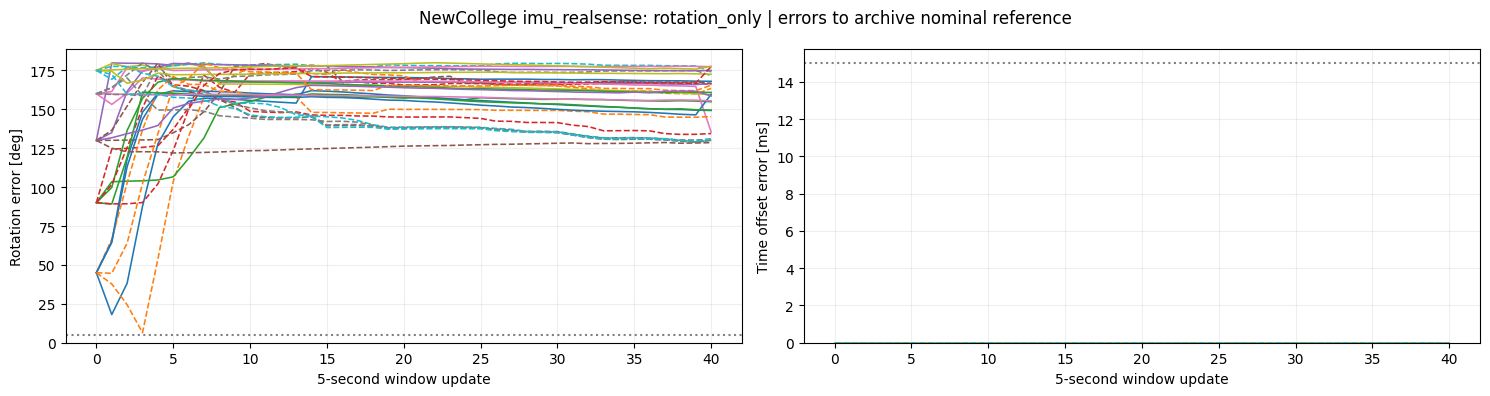

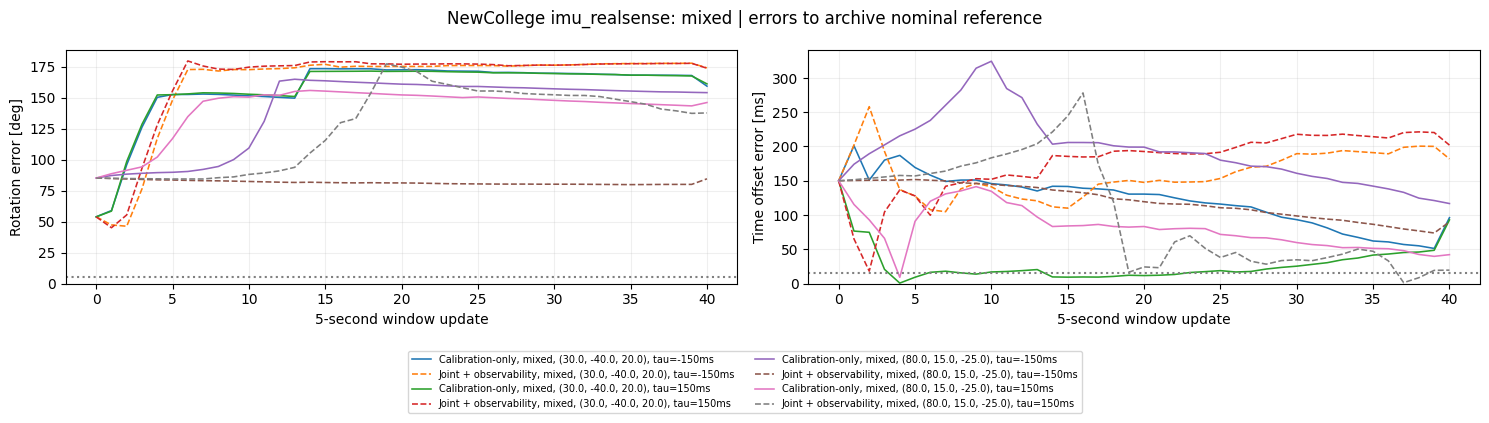

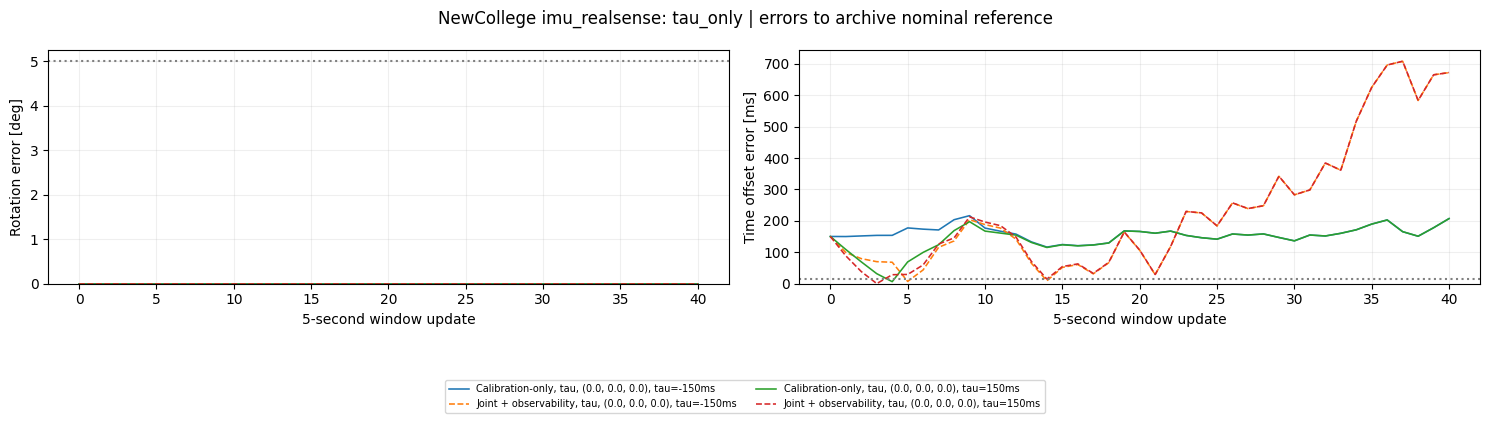

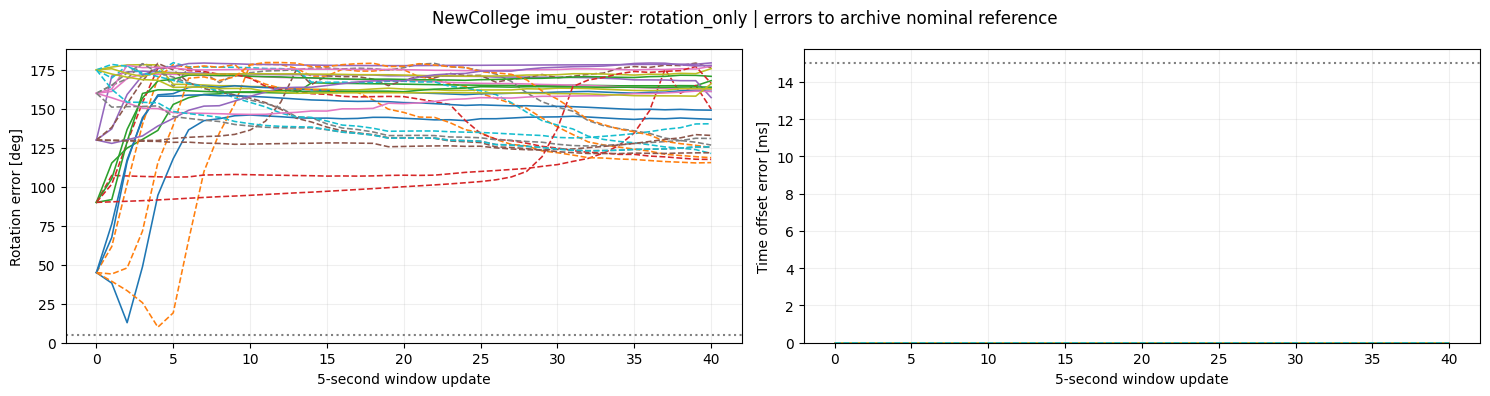

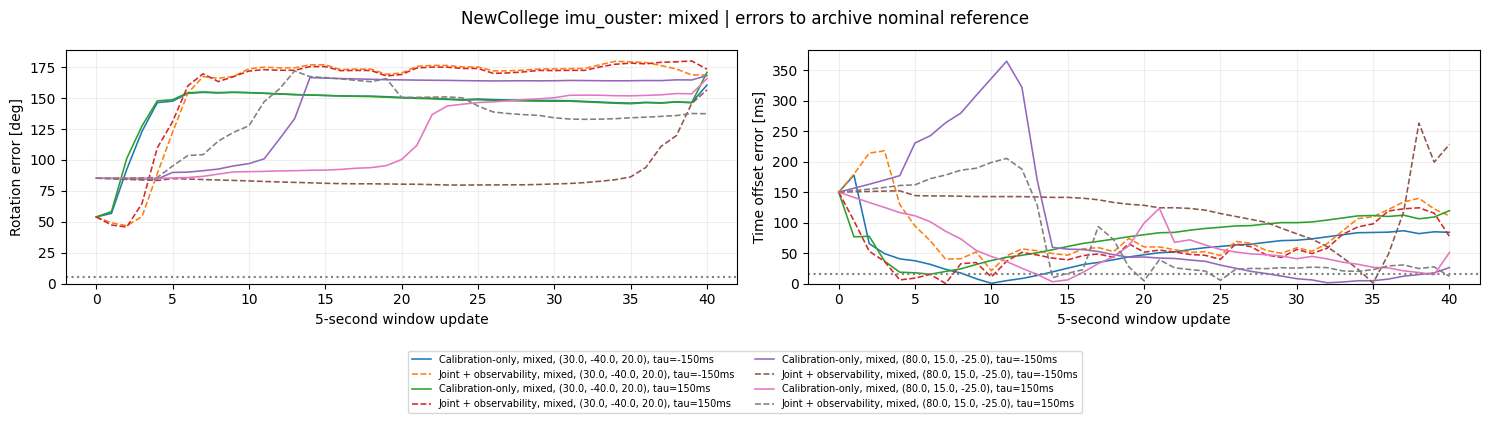

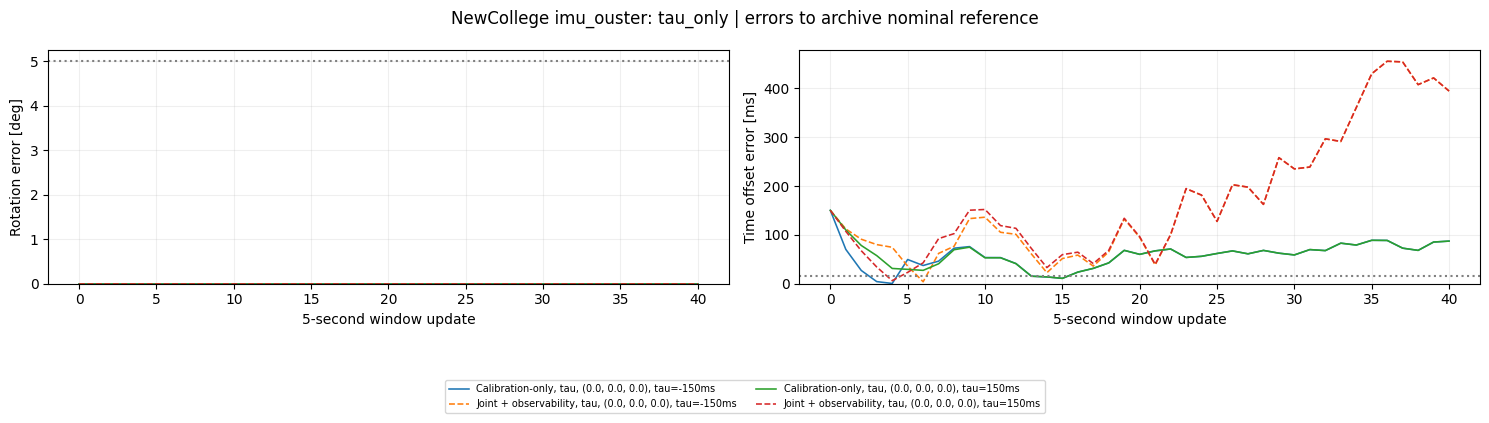

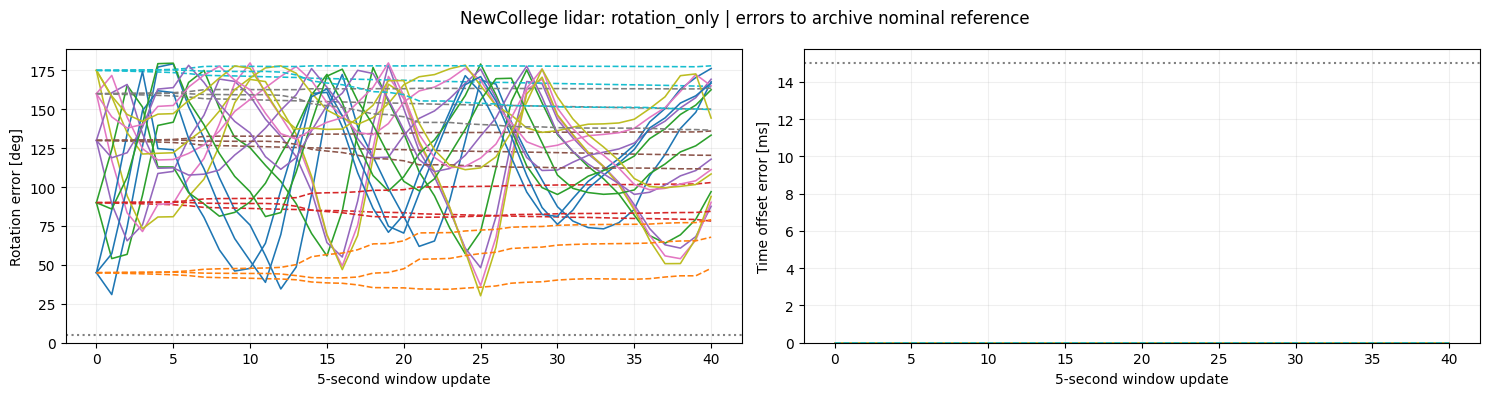

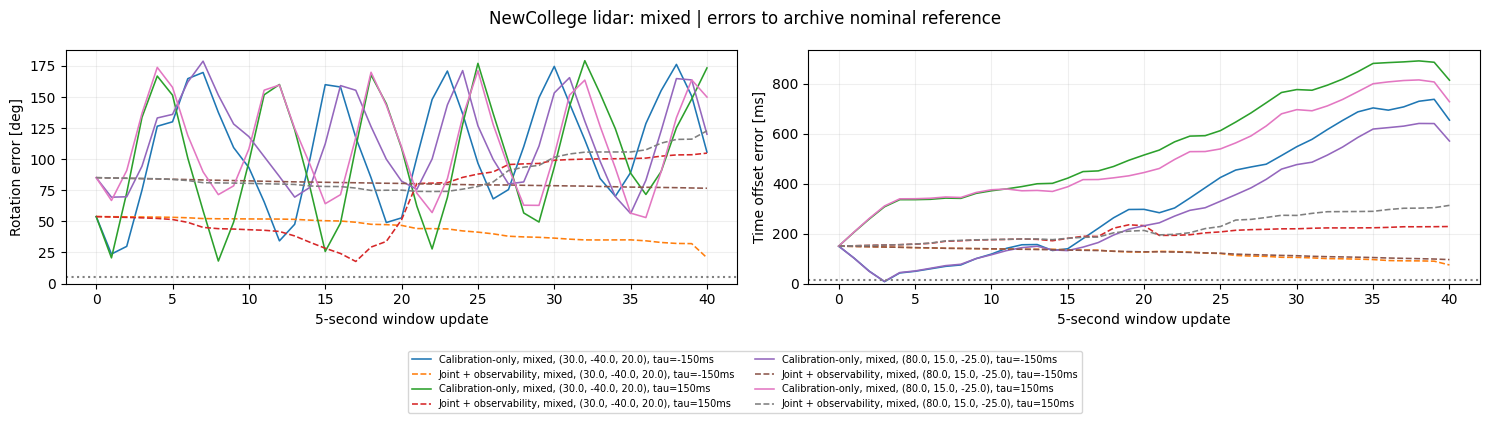

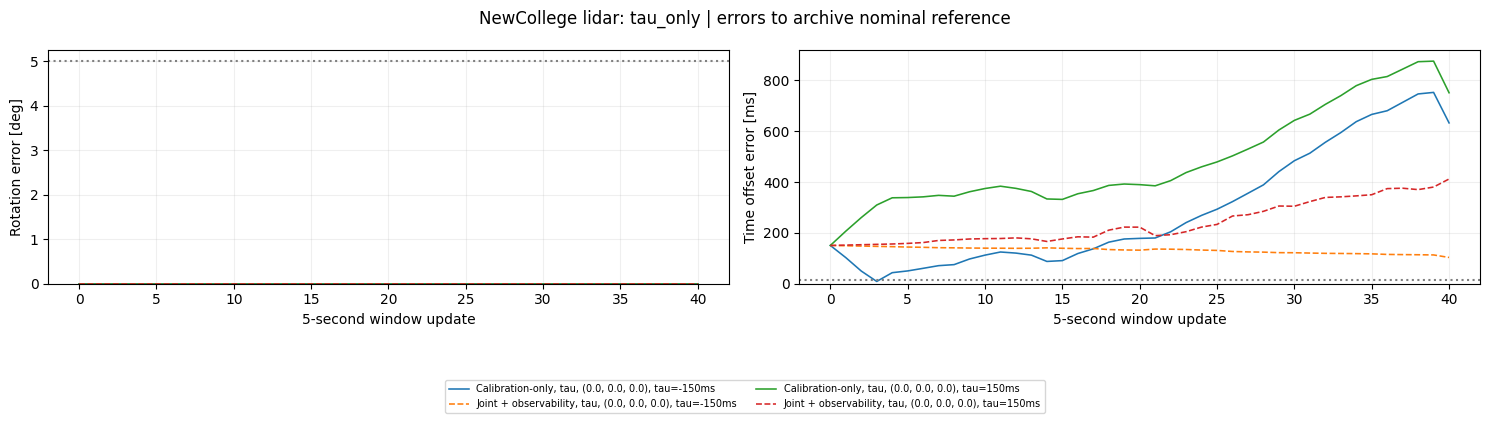

In [35]:
for sensor in CALIBRATION_KEYS:
    for mode in ('rotation_only','mixed','tau_only'):
        frame=rollouts[(rollouts.sensor==sensor)&(rollouts.scenario==mode)]
        if frame.empty:continue
        fig,axs=plt.subplots(1,2,figsize=(15,4),squeeze=False)
        for group_id,group in frame.groupby(['model','axis','initial_rotvec_deg','initial_tau_ms'],sort=False):
            model_name,axis,rotvec,tau=group_id
            group=group.sort_values('step')
            label=f'{model_name}, {axis}, {rotvec}, tau={tau:g}ms'
            linestyle='-' if model_name==MODEL_LABELS[0] else '--'
            axs[0,0].plot(group.step,group.rotation_error_deg,linestyle=linestyle,lw=1.15,label=label)
            axs[0,1].plot(group.step,group.tau_error_ms,linestyle=linestyle,lw=1.15,label=label)
        for ax,threshold,title in zip(axs.ravel(),(ROTATION_CONVERGENCE_DEG,TAU_CONVERGENCE_MS),('Rotation error [deg]','Time offset error [ms]')):
            ax.axhline(threshold,ls=':',color='gray');ax.set(xlabel='5-second window update',ylabel=title);ax.set_ylim(bottom=0);ax.grid(alpha=.2)
        fig.suptitle(f'NewCollege {sensor}: {mode} | errors to archive nominal reference')
        if mode!='rotation_only':fig.legend(*axs[0,0].get_legend_handles_labels(),loc='lower center',bbox_to_anchor=(.5,-.04),ncol=2,fontsize=7)
        fig.tight_layout(rect=(0,.15 if mode!='rotation_only' else 0,1,1))
        if SAVE_RESULTS:fig.savefig(OUT/f'rollout_{sensor}_{mode}.png',dpi=150,bbox_inches='tight')
        plt.show();plt.close(fig)

### Matched single-sensor results summary

These are **not** simultaneous two-IMU corrections. Each row is one selected faulty sensor with both other sensors nominal throughout the rollout. The table below groups the same comparisons that notebook 32 reports for the KAIST test.

In [36]:
# Summarize matched single-fault rollouts without introducing a separate cold-start protocol.
matched_summary = rollout_summary.groupby(['model', 'sensor', 'scenario'], as_index=False).agg(
    count=('final_rot_deg', 'size'),
    initial_rotation_deg=('initial_rot_deg', 'mean'),
    final_rotation_deg=('final_rot_deg', 'mean'),
    best_rotation_deg=('best_rot_deg', 'mean'),
    final_tau_error_ms=('final_tau_ms', 'mean'),
    stable_convergence_fraction=('stable_convergence', 'mean'),
)
display(matched_summary.round(3))
if SAVE_RESULTS:
    matched_summary.to_csv(OUT / 'matched_single_sensor_rollout_summary.csv', index=False)
print('Matched single-sensor experiment completed for sensors:', tuple(matched_summary['sensor'].unique()))

,model,sensor,scenario,count,initial_rotation_deg,final_rotation_deg,best_rotation_deg,final_tau_error_ms,stable_convergence_fraction
0,Calibration-only,imu_ouster,mixed,4,69.499,166.161,71.106,70.219,0.0
1,Calibration-only,imu_ouster,rotation_only,15,120.000,165.123,123.462,0.000,0.0
2,Calibration-only,imu_ouster,tau_only,2,0.000,0.000,0.000,87.002,0.0
3,Calibration-only,imu_realsense,mixed,4,69.499,155.122,73.303,87.018,0.0
4,Calibration-only,imu_realsense,rotation_only,15,120.000,161.328,121.752,0.000,0.0
5,Calibration-only,imu_realsense,tau_only,2,0.000,0.000,0.000,206.932,0.0
6,Calibration-only,lidar,mixed,4,69.499,137.241,37.812,691.969,0.0
7,Calibration-only,lidar,rotation_only,15,120.000,132.781,72.452,0.000,0.0
8,Calibration-only,lidar,tau_only,2,0.000,0.000,0.000,691.418,0.0
9,Joint + observability,imu_ouster,mixed,4,69.499,158.839,64.287,107.083,0.0


Matched single-sensor experiment completed for sensors: ('imu_ouster', 'imu_realsense', 'lidar')


## 12. Interpretation and limitations

- Five physical measurement streams: two genuine IMUs (gyro/accel) and one genuine LiDAR (relative SE(3) odometry). All three are **calibration variables**. No pseudo-LiDAR is created from the Ouster IMU.
- This notebook reproduces **notebook 32's isolated-fault evaluation**: initialize all three sensor states at their nominal calibration, perturb exactly one sensor, and update only the selected sensor's affected DOFs. Healthy sensors remain nominal for the complete rollout. The network is therefore *given the nominal calibrations of healthy sensors*, intentionally and only for this controlled evaluation.
- The common spatial coordinates are the shared Kalibr `cam0` camera frame (`/camera/infra1/image_rect_raw`), not the LiDAR frame. Nominal LiDAR extrinsics are non-identity and LiDAR perturbations and updates are evaluated normally. The chosen coordinate gauge does not fix LiDAR parameters in the network.
- The provided nominal extrinsics derive from the Kalibr/camera/Ouster-mount chain and are **not independently certified ground truth**. Errors and improvements are relative to these reference values.
- Nominal absolute clock offsets are less certain: RealSense uses the earlier 0.11101 s estimate, Ouster uses a provisional zero unless manually provided, and LiDAR uses zero as a time datum. All are perturbable during isolated experiments, but tau results do not establish absolute clock accuracy.
- The three-sensor 21×21 Fisher cache is evaluated at **nominal calibration**, not the previous independent-identity candidate, and is stored under a different hash. Its LiDAR-measured trajectory is transformed to the common camera frame using non-identity `T_C0_LIDAR`.
- The frozen networks were trained on a different physical sensor arrangement. This experiment tests transfer under the **same oracle single-fault protocol** used by notebook 32; it does not prove out-of-distribution reliability or simultaneous blind fault detection.
- A KAIST example is used as a schema template only, not as measurement input.

Outputs: `one_step_cases.csv`, `one_step_summary.csv`, `rollouts_timeseries.csv`, `rollouts_summary.csv`, `matched_single_sensor_rollout_summary.csv`, plots, nominal-state physical Fisher cache, and `sensor_provenance.json`.